# Physics-constrained sea-ice parameterisation: training and evaluation

**An underdetermined physical closure, not just a one-step SIC predictor.** The target atmospheric GCM does not resolve the ocean state required to determine sea-ice evolution uniquely. The model combines three SIC regimes, distillation, and derivative-based physical penalties to restrict the learned response under both observed and synthetic states.

![Arctic one-year offline rollout](docs/rollout_2017_north.gif)

![Antarctic one-year offline rollout](docs/rollout_2017_south.gif)

*Held-out 2017, 1° grid: ERA5 reference, predicted SIC, and error. Predicted SIC is fed back for a full year; atmospheric forcing remains prescribed from ERA5. This is an offline closed-loop SIC test, **not** a coupled GCM forecast.*

| Held-out year | Arctic correlation | Antarctic correlation | Mean SIC bias (Arctic / Antarctic) |
|---|---:|---:|---:|
| 1992 | 0.965 | 0.957 | +0.016 / +0.024 |
| 1993 | 0.963 | 0.953 | +0.012 / +0.017 |
| 2010 | 0.953 | 0.944 | +0.031 / +0.011 |
| 2017 | 0.961 | 0.952 | +0.023 / +0.017 |

*Saved executed outputs, §13. Training: 1980–1988; validation: 1989–1990. The summer minimum is the most difficult interval.*

The workflow runs from ERA5 processing and cache construction through training, diagnostics, export and year-long offline rollouts. Expensive stages are guarded by flags. **`MASK_DISTILL=True` is the documented offline configuration**, and the package it exports is what `ml_seaice_v4.jl` loads by default. Julia coupled tests are separate from the offline results.


## 1. Configuration

This section defines the data paths, model architectures for the three SIC bands, blending gate, and input features used throughout training and evaluation. Spatial gradients and curvature are calculated consistently with the deployed Julia model and are stored with the exported model configuration.


In [1]:
import os, re, sys, time, json
from pathlib import Path
import numpy as np, torch
# F is used by the classification term in the loss (§4). The extracted code relied on the
# source script's own import, which did not come across with it: without this line every
# training cell raises NameError at the first class_loss, and no amount of defining the
# loss functions reveals it -- only calling them does.
import torch.nn.functional as F

# The repository root. Open this notebook from the repository root and this resolves
# itself; otherwise set SIC_ROOT. Every other path below is relative to it, so the
# layout in README.md is the only thing that has to hold.
ROOT = Path(os.environ.get("SIC_ROOT", Path.cwd())).resolve()
assert (ROOT / "sic_pipeline_lib.py").exists(), (
    f"ROOT={ROOT} does not look like the repository root (no sic_pipeline_lib.py). "
    "Open the notebook from the repository root, or set SIC_ROOT.")
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "rollout_sweep_dev")]
import sic_pipeline_lib as L


def rel(p):
    """Paths print relative to ROOT, so the output of a run is the same on any machine."""
    p = Path(p)
    try:
        return str(p.relative_to(ROOT))
    except ValueError:
        return str(p)


def needs_weights(name):
    """§10 onward evaluate the three trained bands. Without their checkpoints there is
    nothing to evaluate, so the section says so and the notebook still runs to the end."""
    print(f"{name}: not run. The three band checkpoints are not in {rel(CKPT_DIR)}/ yet.")
    print("  run §5-§8 first (set the TRAIN_* flags in §1), then Run All again.")


def stage_skipped(flag, name, what, artifact, cost):
    """What a heavy stage prints when its flag in §1 is off: what it would cost, and
    whether what it produces is already on disk. Run All then walks past the training
    sections and evaluates whatever is there, instead of stopping on an exception."""
    here = Path(artifact).exists()
    print(f"{name}: not run ({cost}).  {flag} = False in §1.")
    print(f"  {what}: {'already on disk' if here else 'NOT on disk'} -> {rel(artifact)}")
    if not here:
        print(f"  the sections below need it; set {flag} = True, or see README.md.")

JLDIR = ROOT / "SpeedyWeather.jl-main/SpeedyWeather/src/parameterizations"
JLSRC = JLDIR / "ml_seaice_v4.jl"
CKPT_DIR = ROOT / "checkpoints_hemisphere_unified_rld_tdps"; CKPT_DIR.mkdir(exist_ok=True)
PROCESSED_DIR = ROOT / "processed"

CACHE_DIR      = ROOT / "cache_curv_lap"            # low + mid, pooled N+S
HIGH_CACHE_DIR = ROOT / "cache_high_wide_curv_lap"  # north high, band widened to [0.65, 1.0]

PACKAGE = "ml_seaice_weights_v4_lapmtas"
BANDS = {
    "low":  (f"{PACKAGE}_unified_low",
             "unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap"),
    "mid":  (f"{PACKAGE}_unified_mid",
             "unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap"),
    "high": (f"{PACKAGE}_north_high",
             "north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap"),
}
# checkpoint-name SUFFIXES, for central_pack_rollout.load(low, high, mid) in the blended battery
SUFFIX = {"low":  "_hw2curvtanh100zeroprop_lap",
          "high": "_hw2curvtanh100statemonog0.3_lap",
          "mid":  "_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap"}

GATE = {"lowsic_gate_center": 0.20,  "lowsic_gate_width": 0.035,
        "highsic_gate_center": 0.65, "highsic_gate_width": 0.05,
        "lowsic_gate_center_south": 0.02, "lowsic_gate_width_south": 0.025}
# the cross column's DEFINITION -- not independent knobs, they move with the weights
COLUMN = {"cross_ref_deg": 2.0, "curvature_tanh_scale": 0.5, "curvature_laplacian": True}
# the deployment-side half of the SAME column. ml_seaice_v4.jl forms
#     q = curvature_k_resolved * q2 + (q1 - q2)
# q1 = physical Laplacian on the immediate neighbours, q2 = the same on a two-cell stencil
# over four. q2 vanishes identically on the two-cell mode (there q1 = +-2, q2 = 0), so k
# CANNOT reach the grid-scale response; on an eight-cell mode q2 carries 85% of q1.
# Training used k = 1, i.e. q = q1 exactly.
DEPLOY = {"curvature_k_resolved": 1.0, "curvature_k_auto": False}

# ---- the plumbing the scripts read from argv/env ---------------------------
_CT, TAG, LAMBDA_DAMP = "_lap", "_hw2curvtanh100", 100.0
SYNTH_PERTURB_STD, HIGH_BAND_LO = 1.5, 0.65
EPOCHS = L.EPOCHS
TRAIN_YEARS, VAL_YEARS, TANH_SCALE = list(range(1980, 1989)), [1989, 1990], 0.5

ARM = "zeroprop"                       # low
BASE = "unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1"
TEACHER_NAME = f"{BASE}_h128{_CT}"     # mid stage 1
WIDTH, LDIST, TEACH = 64, 1.0, "_h128"  # mid stage 2
LAM, SWEEP_LO_MID, SWEEP_HI_MID = 1.0, 0.05, 0.95
MASK_TOS, LAM_TAS, TAS_SYNTH = False, 100.0, 8.0
# MASK_DISTILL: the mid-band student masks over the TEACHER's column set
# ("tas","tdps","rld") and matches the teacher under masking. This is the mid band -- the
# `_md` checkpoint named above is the one the shipped package is built from, so §6 (train),
# §9 (export), the §10 battery and the §2 check all name the same object. It is far more
# robust to a missing input (hide-tas 2.6850 -> 0.8761, hide-tdps 1.6925 -> 0.2764) at a
# cost of 0.0106 single-step pooled CORR and a -0.0045 southern test-set score. Setting it
# False reverts the mid checkpoint to the unmasked band, which pays neither.
MASK_DISTILL = True
if not MASK_DISTILL:
    BANDS["mid"] = (BANDS["mid"][0], BANDS["mid"][1].replace("_md_lap", "_lap"))
    SUFFIX["mid"] = SUFFIX["mid"].replace("_md_lap", "_lap")
LAM_HIGH, MODE, EPS, SWEEP_LO_HIGH = 0.3, "global", 0.003, 0.60
CONSIST, LAM_WIND, WIND_FORM, LAM_ANCHOR = 0.0, 0.0, "pointwise", 0.0

# Nothing heavy runs unless you set these. A stage that is off prints what it would
# cost and whether its output is already on disk, and the notebook carries on, so
# Run All on a fresh clone reaches the evaluation sections either way.
BUILD_CACHE = False          # the caches are already on disk for this run
TRAIN_MID_TEACHER = TRAIN_MID = TRAIN_LOW = TRAIN_HIGH = RUN_EXPORT = True

# §10 onward need the three checkpoints, whether this run trained them or an earlier one
# did. This has to be asked at the point of use, not here: on a fresh clone §1 runs before
# §5-§8 exist, so a value fixed here would switch the whole evaluation section off for the
# very run that just trained the weights.
def have_weights():
    return all((CKPT_DIR / BANDS[b][1] / "best.pt").exists() for b in ("low", "mid", "high"))

print(f"\ndevice={L.DEVICE} epochs={EPOCHS} batch={L.BATCH_SIZE} seed={L.SEED} "
      f"processed/={len(list(PROCESSED_DIR.glob('processed_*.nc')))} files")


device=mps epochs=40 batch=6000 seed=42 processed/=18 files


## 2. Training–deployment consistency

This section checks that the input-feature definitions and numerical constants agree between the Python training configuration, exported model metadata, and Julia implementation. The checks cover the spatial features and other settings needed to evaluate the trained networks consistently in the coupled model.


In [2]:
def jl_default(field):
    m = re.search(rf"^\s*{re.escape(field)}::\w+\s*=\s*([^\s#]+)", JLSRC.read_text(), re.M)
    return None if m is None else m.group(1).rstrip("f0").rstrip("f") or m.group(1)

ok = True
pending = 0     # an artefact a later section still has to write. Not a mismatch: on a fresh
                # clone nothing is exported and no cache is built, and that is the normal
                # state, so it is reported as "--" and does not count against consistency.
for band, (wdir, _) in BANDS.items():
    f, decl = JLDIR / wdir / "curvature.txt", {}
    if not f.exists():
        print(f"--  [{band:>4}] curvature.txt not exported yet; §9 writes it")
        pending += 1
        continue
    for ln in f.read_text().splitlines():
        if "=" in ln and not ln.startswith("#"):
            k, v = ln.split("=", 1); decl[k.strip()] = v.strip()
    good = (decl.get("curvature_laplacian") == "true"
            and float(decl.get("curvature_tanh_scale", "nan")) == COLUMN["curvature_tanh_scale"])
    ok &= good
    print(f"{'ok ' if good else 'BAD'} [{band:>4}] curvature.txt {decl}")

for band, cdir, pat in [("low", CACHE_DIR, "north_train_lowband_rld_tdps_gradbasis.npz"),
                        ("mid", CACHE_DIR, "north_train_midband_rld_tdps_gradbasis.npz"),
                        ("high", HIGH_CACHE_DIR, "north_train_highband_rld_gradbasis.npz")]:
    f = cdir / pat
    if not f.exists():
        print(f"--  [{band:>4}] cache not built yet; §3 writes {rel(f)}")
        pending += 1
        continue
    z = np.load(f)
    got = (bool(z["curvature_laplacian"]), float(z["curvature_tanh_scale"]))
    good = got == (COLUMN["curvature_laplacian"], COLUMN["curvature_tanh_scale"]); ok &= good
    print(f"{'ok ' if good else 'BAD'} [{band:>4}] cache laplacian={got[0]} tanh={got[1]} "
          f"band=[{float(z['sic_band_lo'])}, {float(z['sic_band_hi'])}] n={z['X'].shape[0]:,}")

for field, want in list(GATE.items()) + [("cross_ref_deg", COLUMN["cross_ref_deg"]),
                                         ("curvature_tanh_scale", COLUMN["curvature_tanh_scale"]),
                                         ("curvature_k_resolved", DEPLOY["curvature_k_resolved"])]:
    got = jl_default(field)
    good = got is not None and abs(float(got) - float(want)) < 1e-12; ok &= good
    print(f"{'ok ' if good else 'BAD'} {field:<26} want={want:<8} ml_seaice_v4.jl={got}")
for field, want in [("curvature_laplacian", "true"), ("curvature_k_auto", "false")]:
    got = jl_default(field); good = got == want; ok &= good
    print(f"{'ok ' if good else 'BAD'} {field:<26} want={want:<8} ml_seaice_v4.jl={got}")
# The three directories §9 writes are ml_seaice_v4.jl's own defaults, so the Julia model
# needs no weights_dir_* argument. A mismatch here means the notebook and the component
# disagree about which weights are deployed, which is a failure, not a configuration note.
for band, (wdir, ckpt) in BANDS.items():
    g1 = wdir in JLSRC.read_text(); g2 = (CKPT_DIR / ckpt / "best.pt").exists()
    ok &= g1
    print(f"{'ok ' if g1 else 'BAD'} weights_dir {band:<5} {wdir}   "
          f"checkpoint {'present' if g2 else 'ABSENT'}")

if not ok:
    print("\nMISMATCH -- resolve before training or exporting")
elif pending:
    print(f"\nCONSISTENT so far. {pending} artefact(s) not written yet, marked -- above; "
          "the sections that write them say what to switch on.")
else:
    print("\nALL CONSISTENT")

ok  [ low] curvature.txt {'cross_columns': '3', 'curvature_tanh_scale': '0.5', 'curvature_laplacian': 'true'}
ok  [ mid] curvature.txt {'cross_columns': '3', 'curvature_tanh_scale': '0.5', 'curvature_laplacian': 'true'}
ok  [high] curvature.txt {'cross_columns': '3', 'curvature_tanh_scale': '0.5', 'curvature_laplacian': 'true'}
ok  [ low] cache laplacian=True tanh=0.5 band=[0.0, 0.1] n=27,614
ok  [ mid] cache laplacian=True tanh=0.5 band=[0.1, 0.9] n=198,987
ok  [high] cache laplacian=True tanh=0.5 band=[0.65, 1.0] n=762,529
ok  lowsic_gate_center         want=0.2      ml_seaice_v4.jl=0.2
ok  lowsic_gate_width          want=0.035    ml_seaice_v4.jl=0.035
ok  highsic_gate_center        want=0.65     ml_seaice_v4.jl=0.65
ok  highsic_gate_width         want=0.05     ml_seaice_v4.jl=0.05
ok  lowsic_gate_center_south   want=0.02     ml_seaice_v4.jl=0.02
ok  lowsic_gate_width_south    want=0.025    ml_seaice_v4.jl=0.025
ok  cross_ref_deg              want=2.0      ml_seaice_v4.jl=2.
ok  curv

## 3. Training data preparation

Daily ERA5 fields are converted into training arrays containing local SIC, atmospheric forcing, recent history, spatial gradients, curvature, and the following day's SIC tendency. Separate caches provide the appropriate samples and normalisation for each concentration band. Low- and mid-SIC data include both hemispheres; the high-SIC data use the Arctic and their own concentration range. Training covers 1980–1988, validation 1989–1990, and later years are reserved for testing in §13.


In [3]:
if not BUILD_CACHE:
    stage_skipped("BUILD_CACHE", "§3 training caches", "the band caches",
                  CACHE_DIR / "north_train_midband_rld_tdps_gradbasis.npz", "hours")
else:
    OUT_LOWMID, OUT_HIGH = CACHE_DIR, HIGH_CACHE_DIR

    from build_cache_v2 import build_cache

    for d in (OUT_LOWMID, OUT_HIGH):
        d.mkdir(exist_ok=True)
    TRAIN_YEARS = list(range(1980, 1989))
    VAL_YEARS = [1989, 1990]
    TANH_SCALE = 0.5                       # unchanged: the zonal coefficient is normalised to 1
    BAND_EDGES = {"low": (0.0, 0.1), "mid": (0.1, 0.9)}
    LAT_SLICE = {"north": (140, 180), "south": (0, 40)}

    for hemi in ("north", "south"):
        lat_lo, lat_hi = LAT_SLICE[hemi]
        for band in ("low", "mid"):
            lo, hi = BAND_EDGES[band]
            for split, years in (("train", TRAIN_YEARS), ("val", VAL_YEARS)):
                out_path = OUT_LOWMID / f"{hemi}_{split}_{band}band_rld_tdps_gradbasis.npz"
                print(f"=== {out_path} (isotropic curvature, tanh/{TANH_SCALE}) ===", flush=True)
                build_cache(
                    files=[str(PROCESSED_DIR / f"processed_{y}.nc") for y in years],
                    out_path=out_path, hemisphere=hemi,
                    lat_slice_lo=lat_lo, lat_slice_hi=lat_hi,
                    spatial_sigma=0.0, sic_band_lo=lo, sic_band_hi=hi,
                    history_h=3, rollout_k=3,
                    include_rld=True, include_tdps=True,
                    gradient_basis_cross=True, curvature_cross=True,
                    curvature_tanh_scale=TANH_SCALE, curvature_laplacian=True,
                    band_lo_inclusive=(band == "low"), zero_cap_frac=(0.20 if band == "low" else None),
                )
    for split, years in (("train", TRAIN_YEARS), ("val", VAL_YEARS)):
        out_path = OUT_HIGH / f"north_{split}_highband_rld_gradbasis.npz"
        print(f"=== {out_path} (SIC [0.65,1.0], isotropic curvature) ===", flush=True)
        build_cache(
            files=[str(PROCESSED_DIR / f"processed_{y}.nc") for y in years],
            out_path=out_path, hemisphere="north",
            lat_slice_lo=140, lat_slice_hi=180,
            spatial_sigma=0.0, sic_band_lo=0.65, sic_band_hi=1.0,
            history_h=3, rollout_k=3,
            include_rld=True, include_tdps=False,
            gradient_basis_cross=True, curvature_cross=True,
            curvature_tanh_scale=TANH_SCALE, curvature_laplacian=True,
        )
    print("\nBUILD_CACHE_CURV_ISO_DONE")

§3 training caches: not run (hours).  BUILD_CACHE = False in §1.
  the band caches: already on disk -> cache_curv_lap/north_train_midband_rld_tdps_gradbasis.npz


## 4. Training objective and physical constraints

The training loss combines supervised SIC-tendency prediction with classification terms and derivative-based physical regularisation. Because the atmospheric model does not explicitly resolve the ocean state, these constraints help select physically plausible responses among models with similar predictive accuracy.

- **Radiative forcing:** penalise an increase in predicted ice growth under stronger relevant radiative forcing, using observed and synthetically perturbed inputs.
- **Coherent warming:** constrain the predicted response to simultaneous warming of relevant thermodynamic inputs.
- **SIC feedback:** regulate the dependence of the update on the current ice concentration, including high-concentration equilibrium behaviour.

The penalties act on sampled inputs and encourage the desired behaviour; they are not mathematical guarantees for every possible state.


In [4]:
def sic_weight_symmetric(sic, scale, floor=1.0):
    return floor + scale * sic * (1.0 - sic)

def sic_weight_linear_low(sic, scale, floor=1.0):
    return floor + scale * sic / 0.1

def sic_weight_asym_taper_high(sic, scale=2.5, floor=1.0):
    return floor + scale * (1.0 - sic) / (1.0 - HIGH_BAND_LO)

def label_fn_changegate(true_0, valid, tau_unchanged):
    return (true_0.abs() >= tau_unchanged).long(), valid

def label_fn_incdec(true_0, valid, tau=0.02):
    class_valid = valid & (true_0.abs() >= tau)
    return (true_0 < 0).long(), class_valid

In [5]:
def batch_loss_mono_sep_radrobust(model, x, y_target, ocean_frac, sic_raw, tos_raw, sic_hist0, base_target_stats,
                                   rad_col_a, rad_col_b, sic_weight_fn, label_fn, lambda_class, lambda_mono,
                                   lambda_mono_synth, synth_perturb_std,
                                   curv_col=None, lambda_damp=0.0, curv_norm=None, grad_col=None, grad_norm=None,
                                   label_smoothing=0.0, wind_col=None, lambda_wind=0.0, wind_form="pointwise",
                                   anchor_cols=None, anchor_targets=None, lambda_anchor=0.0,
                                   dir_cols=None, dir_weights=None, lambda_tas=0.0, tas_synth_std=0.0):
    valid = ocean_frac > 0
    mean, std = base_target_stats
    x = x.clone().requires_grad_(True)
    pred_0, _, _, class_logits_0 = model(x, sic_raw, tos_raw, sic_hist0)
    true_0 = y_target * std + mean
    w0 = sic_weight_fn(sic_raw)
    loss_0 = torch.mean(w0[valid] * (pred_0[valid] - true_0[valid]) ** 2)

    if lambda_mono > 0 or lambda_damp > 0 or lambda_wind > 0 or lambda_anchor > 0 or lambda_tas > 0:
        grad_x, = torch.autograd.grad(pred_0.sum(), x, create_graph=True)
        mono_penalty = ((torch.mean(torch.relu(grad_x[valid, rad_col_a]) ** 2)
                          + torch.mean(torch.relu(grad_x[valid, rad_col_b]) ** 2))
                        if lambda_mono > 0 else x.sum() * 0.0)
    else:
        mono_penalty = x.sum() * 0.0

    # Optional wind-sign regulariser: constrain the batch-mean response when configured; a pointwise sign is stronger than the observational evidence.
    if lambda_wind > 0 and wind_col is not None:
        g_w = grad_x[valid, wind_col]
        wind_penalty = (torch.relu(-g_w.mean()) ** 2 if wind_form == "mean"
                        else torch.mean(torch.relu(-g_w) ** 2))
    else:
        wind_penalty = x.sum() * 0.0

    # Optional response-gradient anchor: prevent a wind-only penalty from flattening unrelated forcing sensitivities through the shared backbone.
    if lambda_anchor > 0 and anchor_cols is not None:
        anchor_penalty = sum((grad_x[valid, col].mean() - float(tgt)) ** 2
                             for col, tgt in zip(anchor_cols, anchor_targets))
    else:
        anchor_penalty = x.sum() * 0.0

    # Coherent warming penalty: differentiate along joint tas/tdps warming in physical units; synthetic perturbations probe rare cold/dense-ice states.
    if lambda_tas > 0 and dir_cols is not None:
        dw = torch.as_tensor(dir_weights, dtype=x.dtype, device=x.device)
        D = sum(dw[i] * grad_x[valid, c] for i, c in enumerate(dir_cols))
        tas_pen = torch.mean(torch.relu(D) ** 2)
        if tas_synth_std > 0:
            x_t = x.detach().clone()
            kick = torch.randn(x_t.shape[0], device=x_t.device) * tas_synth_std   # kelvin
            for i, c in enumerate(dir_cols):
                x_t[:, c] = x_t[:, c] + kick * dw[i]
            x_t.requires_grad_(True)
            pred_t, _, _, _ = model(x_t, sic_raw, tos_raw, sic_hist0)
            grad_t, = torch.autograd.grad(pred_t.sum(), x_t, create_graph=True)
            Dt = sum(dw[i] * grad_t[valid, c] for i, c in enumerate(dir_cols))
            tas_pen = tas_pen + torch.mean(torch.relu(Dt) ** 2)
    else:
        tas_pen = x.sum() * 0.0

    if lambda_mono_synth > 0:
        x_synth = x.detach().clone()
        noise_a = torch.randn(x_synth.shape[0], device=x_synth.device) * synth_perturb_std
        noise_b = torch.randn(x_synth.shape[0], device=x_synth.device) * synth_perturb_std
        x_synth[:, rad_col_a] = x_synth[:, rad_col_a] + noise_a
        x_synth[:, rad_col_b] = x_synth[:, rad_col_b] + noise_b
        x_synth.requires_grad_(True)
        pred_synth, _, _, _ = model(x_synth, sic_raw, tos_raw, sic_hist0)
        grad_synth, = torch.autograd.grad(pred_synth.sum(), x_synth, create_graph=True)
        mono_penalty_synth = (torch.mean(torch.relu(grad_synth[valid, rad_col_a]) ** 2)
                               + torch.mean(torch.relu(grad_synth[valid, rad_col_b]) ** 2))
    else:
        mono_penalty_synth = x.sum() * 0.0

    # ---- one-sided curvature-damping penalty (2026-09-29) --------------------
    # Holding every other input fixed, raising the zonal curvature (W+E)/2 - C must not make the
    # tendency more negative: if both zonal neighbours carry more ice than the centre, the centre
    # must not lose ice because of it. Only the WRONG SIGN is punished -- no damping strength is
    # prescribed -- exactly like the radiation monotonicity penalty above, which is why this reuses
    # its autograd machinery with the sign flipped.
    #
    # Why it is not a blanket smoother: for a zonal wave of wavenumber k the curvature carries a
    # factor (cos k - 1), which is 2 at the 2-cell mode and 0.19 at a 10-cell mode, so a linear
    # response to this channel acts ~10x harder on the grid-scale mode. And an ice EDGE is
    # gradient-dominated with near-zero curvature (C=0.5, W=1, E=0 gives grad 0.5, curv 0), so the
    # constraint leaves it alone. That orthogonality is what the gradient basis bought.
    #
    # The synthetic points are essential and their range is not a tuning knob: SIC in [0,1] bounds
    # the raw curvature to [-1, 1], while the TRAINING distribution's curvature has std 0.046, so a
    # full checkerboard sits ~21 sigma out and the online spoke regions were measured at ~15 sigma.
    # Constraining only near the data would leave the model unconstrained exactly where it is
    # actually evaluated, which is how the unpenalised 3-column retrain ended up AMPLIFYING the
    # checkerboard in the north (growth 1.42 per 5-day step) while scoring fine on single-step
    # validation. Real points are included too, but they are far too rare to carry the constraint
    # (0.20% of low-band points, 0.41% of high-band, 5.25% of mid-band).
    if lambda_damp > 0 and curv_col is not None:
        c_mean, c_std = curv_norm
        g_mean, g_std = grad_norm

        def extremum(xx):
            """Both zonal neighbours on the SAME side of the centre, i.e. the centre is a local
            extremum along the latitude circle rather than a point on a slope (user, 2026-09-29).
            With w = W - C and e = E - C, grad = (w-e)/2 and curv = (w+e)/2, so sign(w) == sign(e)
            is EXACTLY |curv| > |grad| (verified numerically). This is where "both sides carry more
            ice, so the centre should not lose ice" actually means what it says: a positive curvature
            alone does not imply the centre is below both neighbours -- W=1, E=0, C=0.3 has curvature
            +0.2 while the centre sits ABOVE E. Those are ice-edge points on a monotone slope, where
            a diffusive response would smear exactly the edge the model already renders too smooth
            (measured: south 0.0102-0.0131 against ERA5's 0.0446). The mask drops them: on ERA5 2 deg
            mid-band points it keeps 33%, whose mean |grad| is 0.048 against 0.118 for those dropped,
            and it keeps a pure checkerboard while rejecting a sharp edge.
            Comparison must be in RAW units -- the two columns are normalized by different std."""
            rc = xx[:, curv_col] * c_std + c_mean
            rg = xx[:, grad_col] * g_std + g_mean
            return rc.abs() > rg.abs()

        def one_sided(g, m):
            sel = valid & m
            return torch.mean(torch.relu(-g[sel]) ** 2) if sel.any() else g.sum() * 0.0

        damp_real = one_sided(grad_x[:, curv_col], extremum(x))
        x_curv = x.detach().clone()
        raw = (torch.rand(x_curv.shape[0], device=x_curv.device) * 2.0 - 1.0)   # raw curvature in [-1, 1]
        x_curv[:, curv_col] = (raw - c_mean) / c_std
        x_curv.requires_grad_(True)
        pred_curv, _, _, _ = model(x_curv, sic_raw, tos_raw, sic_hist0)
        grad_curv, = torch.autograd.grad(pred_curv.sum(), x_curv, create_graph=True)
        damp_synth = one_sided(grad_curv[:, curv_col], extremum(x_curv))
        damp_penalty = damp_real + damp_synth
    else:
        damp_penalty = x.sum() * 0.0

    class_labels, class_valid = label_fn(true_0, valid)
    if class_valid.sum() > 0:
        # Optional label smoothing reduces overconfident change-direction classification; default zero preserves earlier experiments.
        class_loss = F.cross_entropy(class_logits_0[class_valid], class_labels[class_valid],
                                     label_smoothing=label_smoothing)
    else:
        class_loss = x.sum() * 0.0

    loss = (loss_0 + lambda_class * class_loss + lambda_mono * mono_penalty
            + lambda_mono_synth * mono_penalty_synth + lambda_damp * damp_penalty
            + lambda_wind * wind_penalty + lambda_anchor * anchor_penalty
            + lambda_tas * tas_pen)
    return loss, valid.detach()

In [6]:
def run_epoch_mono_sep_radrobust(model, loader, optimizer, device, base_target_stats, rad_col_a, rad_col_b,
                                  sic_weight_fn, label_fn, lambda_class, lambda_mono, lambda_mono_synth,
                                  synth_perturb_std, curv_col=None, lambda_damp=0.0, curv_norm=None, grad_col=None, grad_norm=None):
    train_mode = optimizer is not None
    model.train(mode=train_mode)
    tot_loss = tot_n = 0.0
    for batch in loader:
        x, y_target, ocean_frac, sic_raw, tos_raw, sic_hist0, x_future, x_future_raw = [
            b.to(device=device, dtype=torch.float32) for b in batch]
        if train_mode:
            optimizer.zero_grad(set_to_none=True)
        loss, valid = batch_loss_mono_sep_radrobust(model, x, y_target, ocean_frac, sic_raw, tos_raw, sic_hist0,
                                                     base_target_stats, rad_col_a, rad_col_b, sic_weight_fn, label_fn,
                                                     lambda_class, lambda_mono, lambda_mono_synth, synth_perturb_std,
                                                     curv_col=curv_col, lambda_damp=lambda_damp, curv_norm=curv_norm,
                                                     grad_col=grad_col, grad_norm=grad_norm)
        if train_mode:
            loss.backward(); optimizer.step()
        n = int(valid.sum().item())
        if n == 0: continue
        tot_loss += loss.item() * n; tot_n += n
    return tot_loss / max(tot_n, 1)

def train_pooled(band, model_cls, sic_weight_fn, label_fn, lambda_class, lambda_mono, save_name):
    L.set_seed(L.SEED)
    feature_set = "sic+sst+rsds+rld+sfcwind+tas+tdps"
    train_ds, val_ds, train_loader, val_loader = L.make_pooled_loaders(
        str(CACHE_DIR / f"north_train_{band}band_rld_tdps_gradbasis.npz"),
        str(CACHE_DIR / f"south_train_{band}band_rld_tdps_gradbasis.npz"),
        str(CACHE_DIR / f"north_val_{band}band_rld_tdps_gradbasis.npz"),
        str(CACHE_DIR / f"south_val_{band}band_rld_tdps_gradbasis.npz"),
        feature_set=feature_set, normalize_phys=True, batch_size=L.BATCH_SIZE, use_cross=True,
    )
    rad_col_a = train_ds.feature_names.index("rsds")
    rad_col_b = train_ds.feature_names.index("rld")
    curv_col = train_ds.feature_names.index("cross_curv_we")
    grad_col = train_ds.feature_names.index("cross_grad_we")
    ci = len(train_ds.cross_mean) - 1          # curvature is the last cross column, grad_we the one before
    curv_norm = (float(train_ds.cross_mean[ci]), float(train_ds.cross_std[ci]))
    grad_norm = (float(train_ds.cross_mean[ci - 1]), float(train_ds.cross_std[ci - 1]))
    print(f"[{save_name}] X shape={train_ds.X.shape} feature_names={train_ds.feature_names}", flush=True)

    model = model_cls(in_dim=train_ds.X.shape[1], hidden=64, depth=4, tau_floor=L.TAU_FLOOR, dt=L.DT,
                       history_h=train_ds.history_h, mom_hidden=16).to(L.DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=L.LR, weight_decay=L.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=1, threshold=1e-4, threshold_mode="rel", cooldown=0, min_lr=1e-6)

    save_dir = CKPT_DIR / save_name
    save_dir.mkdir(parents=True, exist_ok=True)
    best_val = float("inf")
    t0 = time.time()
    for epoch in range(1, L.EPOCHS + 1):
        tr = run_epoch_mono_sep_radrobust(model, train_loader, optimizer, L.DEVICE, train_ds.base_target_stats,
                                           rad_col_a, rad_col_b, sic_weight_fn, label_fn, lambda_class, lambda_mono,
                                           lambda_mono, SYNTH_PERTURB_STD,
                                           curv_col=curv_col, lambda_damp=LAMBDA_DAMP, curv_norm=curv_norm,
                                           grad_col=grad_col, grad_norm=grad_norm)
        va = run_epoch_mono_sep_radrobust(model, val_loader, None, L.DEVICE, train_ds.base_target_stats,
                                           rad_col_a, rad_col_b, sic_weight_fn, label_fn, lambda_class, lambda_mono,
                                           lambda_mono, SYNTH_PERTURB_STD,
                                           curv_col=curv_col, lambda_damp=LAMBDA_DAMP, curv_norm=curv_norm,
                                           grad_col=grad_col, grad_norm=grad_norm)
        scheduler.step(va)
        if va < best_val:
            best_val = va
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_loss": va,
                        "in_dim": train_ds.X.shape[1], "feature_names": train_ds.feature_names},
                       save_dir / "best.pt")
        if epoch % 10 == 0 or epoch == 1:
            print(f"[{save_name}] epoch {epoch:03d} train_loss={tr:.5f} val_loss={va:.5f}", flush=True)
    elapsed = (time.time() - t0) / 60

    ckpt = torch.load(save_dir / "best.pt", map_location=L.DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    preds, trues = L.collect_predictions(model, val_loader, L.DEVICE, train_ds.base_target_stats)
    hemi_valid = val_ds.hemi_label[val_ds.ocean > 0]

    results = {}
    for name, code in [("north", 0), ("south", 1)]:
        m = hemi_valid == code
        corr = float(np.corrcoef(preds[m], trues[m])[0, 1])
        rmse = float(np.sqrt(np.mean((preds[m] - trues[m]) ** 2)))
        results[name] = dict(corr=corr, rmse=rmse, n=int(m.sum()))
        print(f"[{save_name}/{name}] best_epoch={ckpt['epoch']} n={m.sum()} CORR={corr:.5f} RMSE={rmse:.5f}", flush=True)
    print(f"[{save_name}] elapsed={elapsed:.1f}min", flush=True)
    return results

def train_high_single(save_name):
    L.set_seed(L.SEED)
    feature_set = "sic+sst+rsds+rld+sfcwind+tas"
    train_ds, val_ds, train_loader, val_loader = L.make_loaders(
        str(HIGH_CACHE_DIR / "north_train_highband_rld_gradbasis.npz"),
        str(HIGH_CACHE_DIR / "north_val_highband_rld_gradbasis.npz"),
        feature_set=feature_set, normalize_phys=True, batch_size=L.BATCH_SIZE, use_cross=True,
    )
    rad_col_a = train_ds.feature_names.index("rsds")
    rad_col_b = train_ds.feature_names.index("rld")
    curv_col = train_ds.feature_names.index("cross_curv_we")
    grad_col = train_ds.feature_names.index("cross_grad_we")
    ci = len(train_ds.cross_mean) - 1          # curvature is the last cross column, grad_we the one before
    curv_norm = (float(train_ds.cross_mean[ci]), float(train_ds.cross_std[ci]))
    grad_norm = (float(train_ds.cross_mean[ci - 1]), float(train_ds.cross_std[ci - 1]))
    print(f"[{save_name}] X shape={train_ds.X.shape} feature_names={train_ds.feature_names}", flush=True)

    model = L.RelaxationMoEClassifier(in_dim=train_ds.X.shape[1], hidden=64, depth=4, dropout=0.0,
                                       tau_floor=L.TAU_FLOOR, dt=L.DT, history_h=train_ds.history_h, mom_hidden=16).to(L.DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=L.LR, weight_decay=L.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=1, threshold=1e-4, threshold_mode="rel", cooldown=0, min_lr=1e-6)

    save_dir = CKPT_DIR / save_name
    save_dir.mkdir(parents=True, exist_ok=True)
    best_val = float("inf")
    t0 = time.time()
    for epoch in range(1, L.EPOCHS + 1):
        tr = run_epoch_mono_sep_radrobust(model, train_loader, optimizer, L.DEVICE, train_ds.base_target_stats,
                                           rad_col_a, rad_col_b, lambda x: sic_weight_asym_taper_high(x, scale=2.5), label_fn_incdec,
                                           lambda_class=0.02, lambda_mono=10.0, lambda_mono_synth=10.0,
                                           synth_perturb_std=SYNTH_PERTURB_STD,
                                           curv_col=curv_col, lambda_damp=LAMBDA_DAMP, curv_norm=curv_norm,
                                           grad_col=grad_col, grad_norm=grad_norm)
        va = run_epoch_mono_sep_radrobust(model, val_loader, None, L.DEVICE, train_ds.base_target_stats,
                                           rad_col_a, rad_col_b, lambda x: sic_weight_asym_taper_high(x, scale=2.5), label_fn_incdec,
                                           lambda_class=0.02, lambda_mono=10.0, lambda_mono_synth=10.0,
                                           synth_perturb_std=SYNTH_PERTURB_STD,
                                           curv_col=curv_col, lambda_damp=LAMBDA_DAMP, curv_norm=curv_norm,
                                           grad_col=grad_col, grad_norm=grad_norm)
        scheduler.step(va)
        if va < best_val:
            best_val = va
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_loss": va,
                        "in_dim": train_ds.X.shape[1], "feature_names": train_ds.feature_names},
                       save_dir / "best.pt")
        if epoch % 10 == 0 or epoch == 1:
            print(f"[{save_name}] epoch {epoch:03d} train_loss={tr:.5f} val_loss={va:.5f}", flush=True)
    elapsed = (time.time() - t0) / 60

    ckpt = torch.load(save_dir / "best.pt", map_location=L.DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    preds, trues = L.collect_predictions(model, val_loader, L.DEVICE, train_ds.base_target_stats)
    corr = float(np.corrcoef(preds, trues)[0, 1])
    rmse = float(np.sqrt(np.mean((preds - trues) ** 2)))
    print(f"[{save_name}] best_epoch={ckpt['epoch']} n={len(preds)} CORR={corr:.5f} RMSE={rmse:.5f} elapsed={elapsed:.1f}min", flush=True)
    return dict(north=dict(corr=corr, rmse=rmse, n=len(preds)))

## 5. Mid-SIC teacher model

The mid-SIC band represents the marginal ice zone and much of the seasonal variability. A 128-unit teacher network is trained with supervised targets and self-distillation on inputs with selected thermodynamic features masked. This encourages predictions to remain useful when an atmospheric input is unavailable or differs from the training data.


In [7]:
if not TRAIN_MID_TEACHER:
    stage_skipped("TRAIN_MID_TEACHER", "§5 mid teacher", "the 128-wide teacher checkpoint",
                  CKPT_DIR / TEACHER_NAME / "best.pt", "about 8 min on an M-series GPU")
else:
    CACHE = CACHE_DIR
    CONSIST, DROP = 1.0, 1.0
    LAM, LMONO, LSMOOTH, LCLASS, HIDDEN = 1.0, 1000.0, 0.0, 0.1, 128
    SWEEP_LO, SWEEP_HI = 0.05, 0.95
    MASK_TOS = False
    SAVE = TEACHER_NAME

    L.set_seed(L.SEED)
    tr, va, trl, val = L.make_pooled_loaders(
        str(CACHE / "north_train_midband_rld_tdps_gradbasis.npz"),
        str(CACHE / "south_train_midband_rld_tdps_gradbasis.npz"),
        str(CACHE / "north_val_midband_rld_tdps_gradbasis.npz"),
        str(CACHE / "south_val_midband_rld_tdps_gradbasis.npz"),
        feature_set="sic+sst+rsds+rld+sfcwind+tas+tdps", normalize_phys=True,
        batch_size=L.BATCH_SIZE, use_cross=True)
    fn = list(tr.feature_names)
    rad_a, rad_b = fn.index("rsds"), fn.index("rld")
    curv_col, grad_col = fn.index("cross_curv_we"), fn.index("cross_grad_we")
    sic_col = fn.index("siconc")
    SIC_MEAN, SIC_STD = float(tr.mean[0]), float(tr.std[0])
    ci = len(tr.cross_mean) - 1
    ekw = dict(curv_col=curv_col, lambda_damp=100.0,
               curv_norm=(float(tr.cross_mean[ci]), float(tr.cross_std[ci])), grad_col=grad_col,
               grad_norm=(float(tr.cross_mean[ci - 1]), float(tr.cross_std[ci - 1])))
    model = L.RelaxationMoEClassifier(in_dim=tr.X.shape[1], hidden=HIDDEN, depth=4, tau_floor=L.TAU_FLOOR,
                                      dt=L.DT, history_h=tr.history_h, mom_hidden=16).to(L.DEVICE)
    print(f"[{SAVE}] lambda_consist={CONSIST} lambda_state={LAM} sweep=({SWEEP_LO},{SWEEP_HI}) epochs={EPOCHS} "
          f"in_dim={tr.X.shape[1]} params={sum(p.numel() for p in model.parameters()):,} "
          f"sic norm mean={SIC_MEAN:.4f} std={SIC_STD:.4f}", flush=True)

    # [2026-10-16] MASK_TOS adds the ocean temperature to the set of channels the masked copy may lose.
    # Why it belongs here. Above concentration 0.60 the ocean temperature is a CONSTANT in the training
    # data, because the reanalysis reports a fill value for sea surface temperature under ice rather
    # than a mixed layer temperature: measured standard deviation 0.0514 K in the 0.60 to 0.80 bin and
    # 0.0013 K in 0.80 to 0.90. The component's response to it there is therefore unconstrained by data
    # and is pure extrapolation from the lower concentrations where it does vary, and it is steep: at
    # concentration 0.90 under warm air, raising tos by one kelvin moves the five day tendency by 0.13.
    # The coupled model presents exactly that, which is why the online component has to clamp tos to the
    # training maximum, and that clamp removes 79 per cent of the Arctic summer melt it would otherwise
    # produce. Teaching the band to reproduce its own full-input answer without tos removes the
    # extrapolated sensitivity, which is what makes the clamp safe to relax.
    #
    # tos enters the network ONLY through this normalised column. RelaxationMoEClassifier.forward takes
    # tos_raw and never reads it, so masking the column is the whole intervention.
    THERMO_COLS = [fn.index(k) for k in (("tas", "tdps", "rld", "tos") if MASK_TOS
                                         else ("tas", "tdps", "rld"))]
    _ONEHOT = torch.zeros(tr.X.shape[1], device=L.DEVICE)
    _ONEHOT[sic_col] = 1.0


    def state_penalty(x, tos_raw):
        """relu(d eq / d c - 1)^2 at synthetic concentrations, each keeping its own sample's forcing.

        c feeds the siconc column, sic_raw and the history at once, so one autograd gradient with
        respect to c is the total derivative, including the 1/std of the normalised column."""
        b = x.shape[0]
        c = (SWEEP_LO + (SWEEP_HI - SWEEP_LO) * torch.rand(b, device=x.device)).requires_grad_(True)
        cn = ((c - SIC_MEAN) / SIC_STD).unsqueeze(-1)
        xs = x.detach() * (1.0 - _ONEHOT) + cn * _ONEHOT
        hist = c.unsqueeze(-1).expand(b, tr.history_h)
        _, eq, _, _ = model(xs, c, tos_raw, hist)
        deq, = torch.autograd.grad(eq.sum(), c, create_graph=True)
        return (torch.relu(deq - 1.0) ** 2).mean(), float((deq > 1.0).float().mean().item())


    def epoch(loader, opt):
        model.train(mode=opt is not None)
        tot = n_tot = pen_tot = fr_tot = 0.0
        for batch in loader:
            x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
            if opt is not None:
                opt.zero_grad(set_to_none=True)
            loss, valid = batch_loss_mono_sep_radrobust(
                model, x, y, oc, sic, tos, hist, tr.base_target_stats, rad_a, rad_b,
                lambda s: sic_weight_symmetric(s, scale=10.0),
                lambda t, v: label_fn_incdec(t, v, tau=0.02), LCLASS, LMONO, LMONO,
                SYNTH_PERTURB_STD, label_smoothing=LSMOOTH, **ekw)
            if LAM > 0:
                p, fr = state_penalty(x, tos)
                loss = loss + LAM * p
                pen_tot += float(p.item()); fr_tot += fr
            if CONSIST > 0:
                # one masked copy per sample, trained to reproduce the model's OWN full-input answer.
                # The target is detached, so this never pulls on the complete-input response surface,
                # which is what plain masked fitting did when it raised the melt onset by 9-12 K.
                with torch.no_grad():
                    full, _, _, _ = model(x, sic, tos, hist)
                which = torch.randint(0, len(THERMO_COLS), (x.shape[0],), device=x.device)
                xm = x.clone()
                for ci, col in enumerate(THERMO_COLS):
                    sel = which == ci
                    if sel.any():
                        xm[sel, col] = 0.0
                masked, _, _, _ = model(xm, sic, tos, hist)
                v = oc > 0
                loss = loss + CONSIST * torch.mean((masked[v] - full[v]) ** 2)
            if opt is not None:
                loss.backward(); opt.step()
            k = int(valid.sum().item())
            if k:
                tot += loss.item() * k; n_tot += k
        nb = max(len(loader), 1)
        return tot / max(n_tot, 1), pen_tot / nb, fr_tot / nb


    opt = torch.optim.AdamW(model.parameters(), lr=L.LR, weight_decay=L.WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1,
                                                     threshold=1e-4, threshold_mode="rel", min_lr=1e-6)
    save_dir = CKPT_DIR / SAVE
    save_dir.mkdir(parents=True, exist_ok=True)
    best, t0 = float("inf"), time.time()
    for e in range(1, EPOCHS + 1):
        t, ptr, ftr = epoch(trl, opt)
        v, _, _ = epoch(val, None)
        sch.step(v)
        if v < best:
            best = v
            torch.save({"model_state": model.state_dict(), "epoch": e, "val_loss": v,
                        "in_dim": tr.X.shape[1], "feature_names": fn, "lambda_state": LAM, "lambda_consist": CONSIST,
                        "mode": "global"}, save_dir / "best.pt")
        if e % 10 == 0 or e == 1:
            print(f"[{SAVE}] epoch {e:03d} train={t:.5f} val={v:.5f} statepen={ptr:.6f} "
                  f"frac_viol={ftr:.4f} ({(time.time()-t0)/60:.1f} min)", flush=True)

    model.load_state_dict(torch.load(save_dir / "best.pt", map_location=L.DEVICE,
                                     weights_only=False)["model_state"])
    preds, trues = L.collect_predictions(model, val, L.DEVICE, tr.base_target_stats)
    print(f"\n[{SAVE}] elapsed={(time.time()-t0)/60:.1f}min best_val={best:.5f}")
    print(f"  pooled: n={len(preds):,} CORR={float(np.corrcoef(preds,trues)[0,1]):.5f} "
          f"RMSE={float(np.sqrt(np.mean((preds-trues)**2))):.5f}")
    print("\nMID_STATEMONO_DONE")

[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] lambda_consist=1.0 lambda_state=1.0 sweep=(0.05,0.95) epochs=40 in_dim=10 params=51,590 sic norm mean=0.6708 std=0.2362


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] epoch 001 train=0.08592 val=0.07129 statepen=0.000121 frac_viol=0.0624 (0.2 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] epoch 010 train=0.05785 val=0.05997 statepen=0.000042 frac_viol=0.1100 (1.9 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] epoch 020 train=0.05441 val=0.05680 statepen=0.000031 frac_viol=0.0671 (3.8 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] epoch 030 train=0.05367 val=0.05667 statepen=0.000031 frac_viol=0.0635 (5.7 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] epoch 040 train=0.05358 val=0.05672 statepen=0.000032 frac_viol=0.0637 (7.5 min)



[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap] elapsed=7.6min best_val=0.05667
  pooled: n=91,011 CORR=0.74447 RMSE=0.06734

MID_STATEMONO_DONE


## 6. Mid-SIC student model

A compact 13,574-parameter network is trained for use in the coupled model. It learns from both the ERA5 targets and the larger teacher's predictions, transferring the teacher's response to masked inputs while reducing the computational cost of inference. The training objective also includes the coherent-warming constraint.


In [8]:
if not TRAIN_MID:
    stage_skipped("TRAIN_MID", "§6 mid student", "the distilled mid checkpoint",
                  CKPT_DIR / BANDS["mid"][1] / "best.pt", "about 8 min on an M-series GPU")
else:
    HD = CACHE_DIR
    SWEEP_LO, SWEEP_HI = SWEEP_LO_MID, SWEEP_HI_MID
    SAVE = BANDS["mid"][1]

    L.set_seed(L.SEED)
    tr, va, trl, val = L.make_pooled_loaders(
        str(HD / "north_train_midband_rld_tdps_gradbasis.npz"),
        str(HD / "south_train_midband_rld_tdps_gradbasis.npz"),
        str(HD / "north_val_midband_rld_tdps_gradbasis.npz"),
        str(HD / "south_val_midband_rld_tdps_gradbasis.npz"),
        feature_set="sic+sst+rsds+rld+sfcwind+tas+tdps", normalize_phys=True,
        batch_size=L.BATCH_SIZE, use_cross=True)
    fn = list(tr.feature_names)
    # the teacher's set is ("tas","tdps","rld"), plus "tos" when the teacher masked it too;
    # matching the teacher under masking only means anything if the column sets agree
    MASK_COLS = [fn.index(k) for k in (("tas", "tdps", "rld", "tos") if MASK_TOS
                                       else (("tas", "tdps", "rld") if MASK_DISTILL else ()))]
    rad_a, rad_b = fn.index("rsds"), fn.index("rld")
    curv_col, grad_col = fn.index("cross_curv_we"), fn.index("cross_grad_we")
    sic_col = fn.index("siconc")
    SIC_MEAN, SIC_STD = float(tr.mean[0]), float(tr.std[0])
    ci = len(tr.cross_mean) - 1
    ekw = dict(curv_col=curv_col, lambda_damp=100.0,
               curv_norm=(float(tr.cross_mean[ci]), float(tr.cross_std[ci])), grad_col=grad_col,
               grad_norm=(float(tr.cross_mean[ci - 1]), float(tr.cross_std[ci - 1])))
    if LAM_TAS > 0:
        # per-kelvin weights: the column is (T - mean)/std, so d/dT = (d/dcolumn)/std
        _wt = [1.0/float(tr.std[fn.index("tas")]), 1.0/float(tr.tdps_std)]
        ekw.update(dir_cols=[fn.index("tas"), fn.index("tdps")], dir_weights=_wt,
                   lambda_tas=LAM_TAS, tas_synth_std=TAS_SYNTH)
        print(f"  warming direction: cols {[fn.index('tas'), fn.index('tdps')]} "
              f"weights {[round(v,4) for v in _wt]} per K, synth kick {TAS_SYNTH} K", flush=True)

    # [2026-10-16] the cache tag is a SUFFIX on every saved name, so the teacher trained on the same
    # cache is f"{BASE}{TEACH}{_CT}". The prefix form below is the old convention and is kept only so
    # that teachers saved before the 2026-10-15 rename are still found; the last fallback is an untagged
    # teacher, which is a deliberate cross-cache choice rather than an accident.
    for _cand in (f"{BASE}{TEACH}{_CT}", f"{_CT}{BASE}{TEACH}", f"{BASE}{TEACH}"):
        _tp = CKPT_DIR / _cand
        if (_tp / "best.pt").exists():
            break
    else:
        raise FileNotFoundError(f"no teacher for TEACH={TEACH!r} CACHE_TAG={_CT!r}")
    print(f"  teacher: {_tp.name}", flush=True)
    tck = torch.load(_tp / "best.pt", map_location=L.DEVICE, weights_only=False)
    TW = int(tck["model_state"]["backbone.0.weight"].shape[0])
    teacher = L.RelaxationMoEClassifier(in_dim=tck["in_dim"], hidden=TW, depth=4, dropout=0.0,
                                        tau_floor=L.TAU_FLOOR, dt=L.DT, history_h=tr.history_h,
                                        mom_hidden=16).to(L.DEVICE)
    teacher.load_state_dict(tck["model_state"])
    teacher.eval()
    for q in teacher.parameters():
        q.requires_grad_(False)

    model = L.RelaxationMoEClassifier(in_dim=tr.X.shape[1], hidden=WIDTH, depth=4, dropout=0.0,
                                      tau_floor=L.TAU_FLOOR, dt=L.DT, history_h=tr.history_h,
                                      mom_hidden=16).to(L.DEVICE)
    npar = sum(q.numel() for q in model.parameters())
    tpar = sum(q.numel() for q in teacher.parameters())
    print(f"[{SAVE}] student width {WIDTH} ({npar:,} params) from teacher width {TW} ({tpar:,}); "
          f"the shipped band is 64 wide at 13,574. lambda_distill={LDIST} epochs={EPOCHS}", flush=True)

    _ONEHOT = torch.zeros(tr.X.shape[1], device=L.DEVICE)
    _ONEHOT[sic_col] = 1.0


    def state_penalty(x, tos_raw):
        """the adopted global contraction bound, unchanged"""
        b = x.shape[0]
        c = (SWEEP_LO + (SWEEP_HI - SWEEP_LO) * torch.rand(b, device=x.device)).requires_grad_(True)
        cn = ((c - SIC_MEAN) / SIC_STD).unsqueeze(-1)
        xs = x.detach() * (1.0 - _ONEHOT) + cn * _ONEHOT
        hist = c.unsqueeze(-1).expand(b, tr.history_h)
        _, eq, _, _ = model(xs, c, tos_raw, hist)
        deq, = torch.autograd.grad(eq.sum(), c, create_graph=True)
        viol = torch.relu(deq - 1.0) ** 2
        return viol.mean(), float((deq > 1.0).float().mean().item())


    def epoch(loader, opt):
        model.train(mode=opt is not None)
        tot = n_tot = dist_tot = 0.0
        for batch in loader:
            x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
            if opt is not None:
                opt.zero_grad(set_to_none=True)
            loss, valid = batch_loss_mono_sep_radrobust(
                model, x, y, oc, sic, tos, hist, tr.base_target_stats, rad_a, rad_b,
                lambda s: sic_weight_symmetric(s, scale=10.0),
                lambda t, v: label_fn_incdec(t, v, tau=0.02), 0.1, 1000.0, 1000.0,
                SYNTH_PERTURB_STD, **ekw)
            if LDIST > 0:
                with torch.no_grad():
                    t_pred, _, _, _ = teacher(x, sic, tos, hist)
                s_pred, _, _, _ = model(x, sic, tos, hist)
                v = oc > 0
                d = torch.mean((s_pred[v] - t_pred[v].detach()) ** 2)
                # [2026-10-16] match the teacher under MASKING as well, not only on complete inputs.
                # A teacher trained for self consistency under a masked channel carries that behaviour
                # in how it answers when the channel is gone, and the student never sees that if it only
                # ever matches the teacher on full inputs. Distilling the masked answer too is what
                # transfers the robustness rather than just the fit.
                if MASK_COLS:
                    which = torch.randint(0, len(MASK_COLS), (x.shape[0],), device=x.device)
                    xm = x.clone()
                    for ci, col in enumerate(MASK_COLS):
                        sel = which == ci
                        if sel.any():
                            xm[sel, col] = 0.0
                    with torch.no_grad():
                        t_m, _, _, _ = teacher(xm, sic, tos, hist)
                    s_m, _, _, _ = model(xm, sic, tos, hist)
                    d = 0.5 * (d + torch.mean((s_m[v] - t_m[v].detach()) ** 2))
                loss = loss + LDIST * d
                dist_tot += float(d.item())
            if LAM > 0:
                p, _ = state_penalty(x, tos)
                loss = loss + LAM * p
            if opt is not None:
                loss.backward(); opt.step()
            k = int(valid.sum().item())
            if k:
                tot += loss.item() * k; n_tot += k
        return tot / max(n_tot, 1), dist_tot / max(len(loader), 1)


    opt = torch.optim.AdamW(model.parameters(), lr=L.LR, weight_decay=L.WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1,
                                                     threshold=1e-4, threshold_mode="rel", min_lr=1e-6)
    save_dir = CKPT_DIR / SAVE
    save_dir.mkdir(parents=True, exist_ok=True)
    best, t0 = float("inf"), time.time()
    for e in range(1, EPOCHS + 1):
        t, dt_ = epoch(trl, opt)
        v, _ = epoch(val, None)
        sch.step(v)
        if v < best:
            best = v
            torch.save({"model_state": model.state_dict(), "epoch": e, "val_loss": v,
                        "in_dim": tr.X.shape[1], "feature_names": fn, "variant": "dist_narrow",
                        "student_width": WIDTH, "teacher": _tp.name,
                        "lambda_distill": LDIST}, save_dir / "best.pt")
        if e % 5 == 0 or e <= 3:
            print(f"[{SAVE}] epoch {e:03d} train={t:.5f} val={v:.5f} distil={dt_:.6f} "
                  f"({(time.time()-t0)/60:.1f} min)", flush=True)

    model.load_state_dict(torch.load(save_dir / "best.pt", map_location=L.DEVICE,
                                     weights_only=False)["model_state"])
    preds, trues = L.collect_predictions(model, val, L.DEVICE, tr.base_target_stats)
    print(f"\n[{SAVE}] elapsed={(time.time()-t0)/60:.1f}min best val={best:.5f}  params={npar:,}")
    print(f"  pooled: n={len(preds):,} CORR={float(np.corrcoef(preds,trues)[0,1]):.5f} "
          f"RMSE={float(np.sqrt(np.mean((preds-trues)**2))):.5f}")
    print("\nMID_DISTILL_NARROW_DONE")

  warming direction: cols [5, 6] weights [0.1518, 0.1315] per K, synth kick 8.0 K


  teacher: unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_h128_lap


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] student width 64 (13,574 params) from teacher width 128 (51,590); the shipped band is 64 wide at 13,574. lambda_distill=1.0 epochs=40


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 001 train=0.10010 val=0.07797 distil=0.006549 (0.2 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 002 train=0.07299 val=0.07146 distil=0.001324 (0.4 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 003 train=0.06738 val=0.06647 distil=0.001091 (0.5 min)


... (5 outputs left out)

[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 030 train=0.05557 val=0.05831 distil=0.000661 (5.4 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 035 train=0.05536 val=0.05828 distil=0.000639 (6.3 min)


[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] epoch 040 train=0.05529 val=0.05793 distil=0.000628 (7.2 min)



[unified_mid_gradbasis_cross_sep_radrobust_hw2curvtanh100selfdist1_dist64_l1_mtas100_md_lap] elapsed=7.2min best val=0.05793  params=13,574
  pooled: n=91,011 CORR=0.73690 RMSE=0.06822

MID_DISTILL_NARROW_DONE


## 7. Low-SIC model and ice-edge transitions

The low-SIC band describes cells near the ice edge, including cells with zero initial ice concentration. Its model separates the probability of a concentration change from the magnitude of that change, accommodating the combination of frequent unchanged cells and occasional substantial changes. The training data include zero-SIC samples to represent ice formation and disappearance consistently.


In [9]:
if not TRAIN_LOW:
    stage_skipped("TRAIN_LOW", "§7 low band", "the low checkpoint",
                  CKPT_DIR / BANDS["low"][1] / "best.pt", "about 2 min on an M-series GPU")
else:
    L.set_seed(L.SEED)
    CACHE_DIR_SAVED = CACHE_DIR            # train_pooled reads the module global
    res_low = train_pooled("low", L.ChangeGateClassifier,
                           lambda x: sic_weight_linear_low(x, scale=2.5),
                           lambda t, v: label_fn_changegate(t, v, tau_unchanged=0.005),
                           lambda_class=0.1, lambda_mono=100000.0,
                           save_name=f"unified_low_gradbasis_cross_sep_radrobust{TAG}{ARM}{_CT}")
    print(res_low)
    assert (CKPT_DIR / BANDS["low"][1] / "best.pt").exists(), \
        "derived name != the one the exporter loads"

[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] X shape=(70260, 10) feature_names=['siconc', 'tos', 'rsds', 'rld', 'sfcwind', 'tas', 'tdps', 'cross_grad_ns', 'cross_grad_we', 'cross_curv_we']


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] epoch 001 train_loss=0.14308 val_loss=0.13477


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] epoch 010 train_loss=0.04940 val_loss=0.04779


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] epoch 020 train_loss=0.03824 val_loss=0.03842


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] epoch 030 train_loss=0.03558 val_loss=0.03605


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] epoch 040 train_loss=0.03503 val_loss=0.03557


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap/north] best_epoch=38 n=6729 CORR=0.70452 RMSE=0.06136


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap/south] best_epoch=38 n=9080 CORR=0.82661 RMSE=0.05074


[unified_low_gradbasis_cross_sep_radrobust_hw2curvtanh100zeroprop_lap] elapsed=1.0min


{'north': {'corr': 0.7045244588401204, 'rmse': 0.06135542690753937, 'n': 6729}, 'south': {'corr': 0.8266096484285336, 'rmse': 0.05073962360620499, 'n': 9080}}


## 8. High-SIC equilibrium regularisation

The high-SIC model is trained to produce controlled feedback near saturated ice conditions. Synthetic samples vary SIC over the selected range while retaining atmospheric forcing, and a derivative penalty discourages update-map slopes outside the specified contraction threshold. This is a sampled, soft constraint on equilibrium behaviour rather than a proof of global uniqueness or stability.


In [10]:
if not TRAIN_HIGH:
    stage_skipped("TRAIN_HIGH", "§8 high band", "the north high checkpoint",
                  CKPT_DIR / BANDS["high"][1] / "best.pt", "about 14 min on an M-series GPU")
else:
    HD = HIGH_CACHE_DIR
    LAM, SWEEP_LO = LAM_HIGH, SWEEP_LO_HIGH
    ANCHOR_REF = BANDS["high"][1]
    SAVE = BANDS["high"][1]


    L.set_seed(L.SEED)
    tr, va, trl, val = L.make_loaders(str(HD / "north_train_highband_rld_gradbasis.npz"),
                                      str(HD / "north_val_highband_rld_gradbasis.npz"),
                                      feature_set="sic+sst+rsds+rld+sfcwind+tas", normalize_phys=True,
                                      batch_size=L.BATCH_SIZE, use_cross=True)
    fn = list(tr.feature_names)
    rad_a, rad_b = fn.index("rsds"), fn.index("rld")
    curv_col, grad_col = fn.index("cross_curv_we"), fn.index("cross_grad_we")
    sic_col = fn.index("siconc")
    SIC_MEAN, SIC_STD = float(tr.mean[0]), float(tr.std[0])
    ci = len(tr.cross_mean) - 1
    ekw = dict(curv_col=curv_col, lambda_damp=100.0,
               curv_norm=(float(tr.cross_mean[ci]), float(tr.cross_std[ci])), grad_col=grad_col,
               grad_norm=(float(tr.cross_mean[ci - 1]), float(tr.cross_std[ci - 1])))
    if LAM_WIND > 0:
        ekw.update(wind_col=fn.index("sfcwind"), lambda_wind=LAM_WIND, wind_form=WIND_FORM)
    if LAM_ANCHOR > 0:
        # targets are the REFERENCE band's own mean gradients, measured on this cache before training
        _ref_ck = torch.load(CKPT_DIR / ANCHOR_REF / "best.pt", map_location=L.DEVICE, weights_only=False)
        _ref = L.RelaxationMoEClassifier(in_dim=tr.X.shape[1],
                                         hidden=int(_ref_ck["model_state"]["backbone.0.weight"].shape[0]),
                                         depth=4, dropout=0.0, tau_floor=L.TAU_FLOOR, dt=L.DT,
                                         history_h=tr.history_h, mom_hidden=16).to(L.DEVICE)
        _ref.load_state_dict(_ref_ck["model_state"]); _ref.eval()
        _wc = fn.index("sfcwind")
        _acols = [c for c in range(tr.X.shape[1]) if c != _wc]
        _tot = np.zeros(tr.X.shape[1]); _n = 0
        for _b in trl:
            _x, _y, _oc, _s, _t, _h, _, _ = [q.to(L.DEVICE, torch.float32) for q in _b]
            _x = _x.clone().requires_grad_(True)
            _p, _, _, _ = _ref(_x, _s, _t, _h)
            _g, = torch.autograd.grad(_p.sum(), _x)
            _v = _oc > 0
            _tot += _g[_v].mean(0).detach().cpu().numpy() * _v.sum().item(); _n += _v.sum().item()
        _tgt = (_tot / _n)[_acols]
        ekw.update(anchor_cols=_acols, anchor_targets=_tgt.tolist(), lambda_anchor=LAM_ANCHOR)
        print(f"  anchor from {ANCHOR_REF}: " +
              "  ".join(f"{fn[c]}={v:+.6f}" for c, v in zip(_acols, _tgt)), flush=True)
    model = L.RelaxationMoEClassifier(in_dim=tr.X.shape[1], hidden=64, depth=4, dropout=0.0,
                                      tau_floor=L.TAU_FLOOR, dt=L.DT, history_h=tr.history_h,
                                      mom_hidden=16).to(L.DEVICE)
    print(f"[{SAVE}] mode={MODE} lambda_state={LAM} lambda_wind={LAM_WIND} eps={EPS} sweep_lo={SWEEP_LO} epochs={EPOCHS} "
          f"params={sum(p.numel() for p in model.parameters()):,} "
          f"sic norm mean={SIC_MEAN:.4f} std={SIC_STD:.4f}", flush=True)

    _ONEHOT = torch.zeros(tr.X.shape[1], device=L.DEVICE)
    _ONEHOT[sic_col] = 1.0


    # tos reaches the network ONLY through this normalised column: RelaxationMoEClassifier.forward
    # takes tos_raw and never reads it, so masking the column is the whole intervention.
    _FN = list(tr.feature_names)
    MASK_COLS = [_FN.index(k) for k in (("tas", "rld", "tos") if MASK_TOS else ("tas", "rld"))]


    def state_penalty(x, tos_raw):
        """d eq / d c at synthetic concentrations, each keeping its own sample's forcing.

        c enters the model in three places (the siconc column, sic_raw, and the history), so the single
        autograd gradient with respect to c is the TOTAL derivative, including the 1/std factor from the
        normalised column. Taking it only on sic_raw would silently drop the column's contribution.
        The history is held at the steady value c, which makes the momentum differences identically zero
        and matches the fixed-point calculation the defect was measured with."""
        b = x.shape[0]
        c = (SWEEP_LO + (1.0 - SWEEP_LO) * torch.rand(b, device=x.device)).requires_grad_(True)
        cn = ((c - SIC_MEAN) / SIC_STD).unsqueeze(-1)
        xs = x.detach() * (1.0 - _ONEHOT) + cn * _ONEHOT
        hist = c.unsqueeze(-1).expand(b, tr.history_h)
        _, eq, _, _ = model(xs, c, tos_raw, hist)
        deq, = torch.autograd.grad(eq.sum(), c, create_graph=True)
        if MODE == "global":
            # A global slope bound would ensure monotonic equilibrium residual; this sampled soft penalty encourages, but does not prove, that property.
            viol = torch.relu(deq - 1.0) ** 2
            return viol.mean(), float((deq > 1.0).float().mean().item())
        w = torch.exp(-((eq - c) / EPS) ** 2).detach()
        # w.sum() is reported because the normalised form hides an empty window: a small penalty can
        # mean the constraint is satisfied OR that no synthetic point landed near a fixed point at all,
        # and those need different responses.
        return torch.sum(w * torch.relu(deq - 1.0) ** 2) / (w.sum() + 1e-6), float(w.sum().item())


    def epoch(loader, opt):
        model.train(mode=opt is not None)
        tot = n_tot = pen_tot = w_tot = 0.0
        for batch in loader:
            x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
            if opt is not None:
                opt.zero_grad(set_to_none=True)
            loss, valid = batch_loss_mono_sep_radrobust(
                model, x, y, oc, sic, tos, hist, tr.base_target_stats, rad_a, rad_b,
                lambda s: sic_weight_asym_taper_high(s, scale=2.5),
                lambda t, v: label_fn_incdec(t, v, tau=0.02), 0.02, 10.0, 10.0, SYNTH_PERTURB_STD, **ekw)
            if CONSIST > 0:
                # one masked copy per sample, trained to reproduce the band's own full input answer
                with torch.no_grad():
                    full, _, _, _ = model(x, sic, tos, hist)
                which = torch.randint(0, len(MASK_COLS), (x.shape[0],), device=x.device)
                xm = x.clone()
                for ci, col in enumerate(MASK_COLS):
                    sel = which == ci
                    if sel.any():
                        xm[sel, col] = 0.0
                masked, _, _, _ = model(xm, sic, tos, hist)
                v = oc > 0
                loss = loss + CONSIST * torch.mean((masked[v] - full[v].detach()) ** 2)
            if LAM > 0:
                p, wsum = state_penalty(x, tos)
                loss = loss + LAM * p
                pen_tot += float(p.item()); w_tot += wsum
            if opt is not None:
                loss.backward(); opt.step()
            k = int(valid.sum().item())
            if k:
                tot += loss.item() * k; n_tot += k
        return tot / max(n_tot, 1), pen_tot / max(len(loader), 1), w_tot / max(len(loader), 1)


    opt = torch.optim.AdamW(model.parameters(), lr=L.LR, weight_decay=L.WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1,
                                                     threshold=1e-4, threshold_mode="rel", min_lr=1e-6)
    save_dir = CKPT_DIR / SAVE
    save_dir.mkdir(parents=True, exist_ok=True)
    best, t0 = float("inf"), time.time()
    for e in range(1, EPOCHS + 1):
        t, ptr, wtr = epoch(trl, opt)
        v, pva, _ = epoch(val, None)
        sch.step(v)
        if v < best:
            best = v
            torch.save({"model_state": model.state_dict(), "epoch": e, "val_loss": v,
                        "in_dim": tr.X.shape[1], "feature_names": fn, "variant": "statemono",
                        "lambda_state": LAM, "eps": EPS, "mode": MODE}, save_dir / "best.pt")
        if e % 5 == 0 or e <= 3:
            print(f"[{SAVE}] epoch {e:03d} train={t:.5f} val={v:.5f} statepen={ptr:.6f} "
                  f"{'frac_viol' if MODE == 'global' else 'sum_w'}={wtr:8.4f} "
                  f"({(time.time()-t0)/60:.1f} min)", flush=True)

    model.load_state_dict(torch.load(save_dir / "best.pt", map_location=L.DEVICE,
                                     weights_only=False)["model_state"])
    preds, trues = L.collect_predictions(model, val, L.DEVICE, tr.base_target_stats)
    X = np.asarray(va.X); tas = (X[:, fn.index("tas")] * va.std[5] + va.mean[5])[va.ocean > 0]
    cuts = np.percentile(tas, [25, 50, 75, 90])
    print(f"\n[{SAVE}] elapsed={(time.time()-t0)/60:.1f}min best_epoch at val={best:.5f}")
    print(f"  pooled: n={len(preds):,} CORR={float(np.corrcoef(preds,trues)[0,1]):.5f} "
          f"RMSE={float(np.sqrt(np.mean((preds-trues)**2))):.5f}")
    for nm, m_ in (("coldest 25%", tas < cuts[0]), ("25-50%", (tas >= cuts[0]) & (tas < cuts[1])),
                   ("50-75%", (tas >= cuts[1]) & (tas < cuts[2])),
                   ("75-90%", (tas >= cuts[2]) & (tas < cuts[3])), ("warmest 10%", tas >= cuts[3])):
        print(f"    {nm:>12s} n={int(m_.sum()):7,d} CORR={float(np.corrcoef(preds[m_],trues[m_])[0,1]):.4f}")
    print("\nHIGH_STATEMONO_DONE")

[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] mode=global lambda_state=0.3 lambda_wind=0.0 eps=0.003 sweep_lo=0.6 epochs=40 params=13,510 sic norm mean=0.9412 std=0.0642


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 001 train=0.02541 val=0.01367 statepen=0.000018 frac_viol=  0.0052 (0.3 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 002 train=0.01297 val=0.01097 statepen=0.000169 frac_viol=  0.0652 (0.7 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 003 train=0.01212 val=0.01074 statepen=0.000034 frac_viol=  0.0392 (1.0 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 005 train=0.01175 val=0.01052 statepen=0.000016 frac_viol=  0.0273 (1.6 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 010 train=0.01134 val=0.01043 statepen=0.000006 frac_viol=  0.0144 (3.1 min)


... (3 outputs left out)

[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 030 train=0.01114 val=0.01042 statepen=0.000005 frac_viol=  0.0104 (9.2 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 035 train=0.01114 val=0.01042 statepen=0.000005 frac_viol=  0.0103 (10.7 min)


[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] epoch 040 train=0.01114 val=0.01042 statepen=0.000005 frac_viol=  0.0105 (12.2 min)



[north_high_gradbasis_cross_sep_radrobust_hw2curvtanh100statemonog0.3_lap] elapsed=12.3min best_epoch at val=0.01040
  pooled: n=160,654 CORR=0.48827 RMSE=0.03189
     coldest 25% n= 40,164 CORR=0.5629
          25-50% n= 40,163 CORR=0.6425
          50-75% n= 40,163 CORR=0.5224
          75-90% n= 24,095 CORR=0.3602
     warmest 10% n= 16,069 CORR=0.4216

HIGH_STATEMONO_DONE


## 9. Model export for Julia

This section exports the trained band networks as binary weights with a text manifest for use by the Julia component without Python at runtime. Normalisation statistics are calculated from the corresponding training caches. The exported configuration can then be checked against the training and deployment definitions in §2.


In [2]:
if not RUN_EXPORT:
    stage_skipped("RUN_EXPORT", "§9 export", "the binary weight package",
                  JLDIR / BANDS["mid"][0] / "w1.bin", "seconds")
else:
    OUT_ROOT, CACHE_DIR_EXPORT, LOW_CACHE = JLDIR, CACHE_DIR, CACHE_DIR
    # Both the checkpoint loaded and the directory written come from BANDS, so this cell
    # cannot export a band other than the one §6 trained.

    def write_bin(path, arr):
        np.asarray(arr, dtype=np.float32).tofile(path)


    def pooled_norm_low_mid(band, cache_dir=None):
        CACHE_DIR = cache_dir if cache_dir is not None else CACHE_DIR_EXPORT
        train_ds, _, _, _ = L.make_pooled_loaders(
            str(CACHE_DIR / f"north_train_{band}band_rld_tdps_gradbasis.npz"),
            str(CACHE_DIR / f"south_train_{band}band_rld_tdps_gradbasis.npz"),
            str(CACHE_DIR / f"north_val_{band}band_rld_tdps_gradbasis.npz"),
            str(CACHE_DIR / f"south_val_{band}band_rld_tdps_gradbasis.npz"),
            feature_set="sic+sst+rsds+rld+sfcwind+tas+tdps", normalize_phys=True, batch_size=L.BATCH_SIZE, use_cross=True,
        )
        print(f"[{band}] cross_mean shape={train_ds.cross_mean.shape} cross_std shape={train_ds.cross_std.shape}")
        return dict(mean=train_ds.mean, std=train_ds.std, cross_mean=train_ds.cross_mean, cross_std=train_ds.cross_std,
                    rld_mean=float(train_ds.rld_mean), rld_std=float(train_ds.rld_std),
                    tdps_mean=float(train_ds.tdps_mean), tdps_std=float(train_ds.tdps_std))


    def north_high_norm():
        # the widened high band ([0.65, 1.0]) has its own cache, and its normalization statistics MUST
        # come from there -- using the old [0.9, 1.0] statistics would silently mis-scale every input
        HIGH_CACHE = HIGH_CACHE_DIR
        train_ds, _, _, _ = L.make_loaders(
            str(HIGH_CACHE / "north_train_highband_rld_gradbasis.npz"),
            str(HIGH_CACHE / "north_val_highband_rld_gradbasis.npz"),
            feature_set="sic+sst+rsds+rld+sfcwind+tas", normalize_phys=True, batch_size=L.BATCH_SIZE, use_cross=True,
        )
        print(f"[high] cross_mean shape={train_ds.cross_mean.shape} cross_std shape={train_ds.cross_std.shape}")
        return dict(mean=train_ds.mean, std=train_ds.std, cross_mean=train_ds.cross_mean, cross_std=train_ds.cross_std,
                    rld_mean=float(train_ds.rld_mean), rld_std=float(train_ds.rld_std))


    def _put_common(put, state_dict):
        for layer in [0, 2, 4, 6]:
            w = state_dict[f"backbone.{layer}.weight"].numpy()
            b = state_dict[f"backbone.{layer}.bias"].numpy()
            put(f"backbone.{layer}.weight", f"backbone_{layer}_weight.bin", w.ravel(), f"{w.shape[0]},{w.shape[1]}")
            put(f"backbone.{layer}.bias", f"backbone_{layer}_bias.bin", b, f"{b.shape[0]}")
        wm = state_dict["momentum_mlp.0.weight"].numpy()
        bm = state_dict["momentum_mlp.0.bias"].numpy()
        put("momentum_mlp.0.weight", "momentum_mlp_0_weight.bin", wm.ravel(), f"{wm.shape[0]},{wm.shape[1]}")
        put("momentum_mlp.0.bias", "momentum_mlp_0_bias.bin", bm, f"{bm.shape[0]}")


    def _put_norm(put, norm, has_tdps):
        put("norm.mean", "norm_mean.bin", norm["mean"], f"{len(norm['mean'])}")
        put("norm.std", "norm_std.bin", norm["std"], f"{len(norm['std'])}")
        put("norm.cross_mean", "norm_cross_mean.bin", norm["cross_mean"], f"{len(norm['cross_mean'])}")
        put("norm.cross_std", "norm_cross_std.bin", norm["cross_std"], f"{len(norm['cross_std'])}")
        put("norm.rld_mean", "norm_rld_mean.bin", [norm["rld_mean"]], "0")
        put("norm.rld_std", "norm_rld_std.bin", [norm["rld_std"]], "0")
        if has_tdps:
            put("norm.tdps_mean", "norm_tdps_mean.bin", [norm["tdps_mean"]], "0")
            put("norm.tdps_std", "norm_tdps_std.bin", [norm["tdps_std"]], "0")


    def export_incdec_v3(state_dict, norm, out_dir, has_tdps):
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        manifest = []

        def put(name, fname, tensor, shape_str):
            write_bin(out_dir / fname, tensor)
            manifest.append(f"{name}\t{shape_str}\t{fname}")

        put("tau_inc_param", "tau_inc_param.bin", [float(state_dict["tau_inc_param"].item())], "1")
        put("tau_dec_param", "tau_dec_param.bin", [float(state_dict["tau_dec_param"].item())], "1")
        _put_common(put, state_dict)
        for head, key in [("class_head", "class_head"), ("inc_head", "inc_head"), ("dec_head", "dec_head")]:
            w = state_dict[f"{key}.weight"].numpy()
            b = state_dict[f"{key}.bias"].numpy()
            put(f"{head}.weight", f"{head}_weight.bin", w.ravel(), f"{w.shape[0]},{w.shape[1]}")
            put(f"{head}.bias", f"{head}_bias.bin", b, f"{b.shape[0]}")
        _put_norm(put, norm, has_tdps)

        with open(out_dir / "manifest.txt", "w") as f:
            f.write("\n".join(manifest) + "\n")
        # The curvature column's definition travels INSIDE the package, next to the weights
        # fitted to it. ml_seaice_v4.jl's initialize! reads this file and errors if the model
        # it is being built into is configured for a different column; without it the Julia
        # side can only warn that it cannot check. sic_pipeline_lib says to call this from
        # every export path, and three separate coupled-run defects came from a caller's flag
        # list drifting away from the weights, so it is not optional.
        L.write_curvature_declaration(out_dir, 3,
                                      curvature_tanh_scale=COLUMN["curvature_tanh_scale"],
                                      curvature_laplacian=COLUMN["curvature_laplacian"])
        print(f"exported -> {rel(out_dir)}  ({len(manifest)} tensors, has_tdps={has_tdps}, "
              f"curvature.txt written)")


    def export_changegate_v3(state_dict, norm, out_dir, has_tdps):
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        manifest = []

        def put(name, fname, tensor, shape_str):
            write_bin(out_dir / fname, tensor)
            manifest.append(f"{name}\t{shape_str}\t{fname}")

        put("tau_changed_param", "tau_changed_param.bin", [float(state_dict["tau_changed_param"].item())], "1")
        _put_common(put, state_dict)
        for head, key in [("class_head", "class_head"), ("changed_head", "changed_head")]:
            w = state_dict[f"{key}.weight"].numpy()
            b = state_dict[f"{key}.bias"].numpy()
            put(f"{head}.weight", f"{head}_weight.bin", w.ravel(), f"{w.shape[0]},{w.shape[1]}")
            put(f"{head}.bias", f"{head}_bias.bin", b, f"{b.shape[0]}")
        _put_norm(put, norm, has_tdps)

        with open(out_dir / "manifest.txt", "w") as f:
            f.write("\n".join(manifest) + "\n")
        # The curvature column's definition travels INSIDE the package, next to the weights
        # fitted to it. ml_seaice_v4.jl's initialize! reads this file and errors if the model
        # it is being built into is configured for a different column; without it the Julia
        # side can only warn that it cannot check. sic_pipeline_lib says to call this from
        # every export path, and three separate coupled-run defects came from a caller's flag
        # list drifting away from the weights, so it is not optional.
        L.write_curvature_declaration(out_dir, 3,
                                      curvature_tanh_scale=COLUMN["curvature_tanh_scale"],
                                      curvature_laplacian=COLUMN["curvature_laplacian"])
        print(f"exported -> {rel(out_dir)}  ({len(manifest)} tensors, has_tdps={has_tdps}, "
              f"curvature.txt written)")


    # --- unified_low (ChangeGateClassifier, WITH tdps, pooled north+south, gradient-basis cross) ---
    ckpt = torch.load(CKPT_DIR / BANDS["low"][1] / "best.pt", map_location="cpu", weights_only=False)
    norm = pooled_norm_low_mid("low", LOW_CACHE)
    export_changegate_v3(ckpt["model_state"], norm, OUT_ROOT / BANDS["low"][0], has_tdps=True)

    # --- unified_mid (RelaxationMoEClassifier, WITH tdps, pooled north+south, gradient-basis cross) ---
    ckpt = torch.load(CKPT_DIR / BANDS["mid"][1] / "best.pt", map_location="cpu", weights_only=False)
    norm = pooled_norm_low_mid("mid")
    export_incdec_v3(ckpt["model_state"], norm, OUT_ROOT / BANDS["mid"][0], has_tdps=True)

    # --- north_high (RelaxationMoEClassifier, no tdps, Arctic-only, gradient-basis cross) ---
    ckpt = torch.load(CKPT_DIR / BANDS["high"][1] / "best.pt", map_location="cpu", weights_only=False)
    norm = north_high_norm()
    export_incdec_v3(ckpt["model_state"], norm, OUT_ROOT / BANDS["high"][0], has_tdps=False)

    print("EXPORT_V4_SELFDIST_WEIGHTS_DONE")

[low] cross_mean shape=(3,) cross_std shape=(3,)
exported -> SpeedyWeather.jl-main/SpeedyWeather/src/parameterizations/ml_seaice_weights_v4_lapmtas_unified_low  (23 tensors, has_tdps=True, curvature.txt written)


[mid] cross_mean shape=(3,) cross_std shape=(3,)
exported -> SpeedyWeather.jl-main/SpeedyWeather/src/parameterizations/ml_seaice_weights_v4_lapmtas_unified_mid  (26 tensors, has_tdps=True, curvature.txt written)


[high] cross_mean shape=(3,) cross_std shape=(3,)
exported -> SpeedyWeather.jl-main/SpeedyWeather/src/parameterizations/ml_seaice_weights_v4_lapmtas_north_high  (24 tensors, has_tdps=False, curvature.txt written)
EXPORT_V4_SELFDIST_WEIGHTS_DONE


## 10. Blended single-step evaluation

The three trained bands are combined through the deployment gate and evaluated on common samples. Results are grouped by initial SIC to show accuracy across concentration regimes. The aggregate melt ratio compares predicted and reference melting budgets and is interpreted as a budget diagnostic rather than a pointwise error measure.


In [3]:
if not have_weights():
    needs_weights("§10 the blended battery")
else:
    import torch, io, contextlib
    # box_emulation runs a box sweep AT IMPORT TIME and, left alone, loads models under its own
    # hard-coded suffix, which maps to a cache this notebook does not build (cache_curv_tanh).
    # _eval_rows imports it only for the gate constants, so the whole cascade would fail on a
    # missing directory. Point it at the suffixes §1 derived before any of it is imported.
    os.environ['SIC_BOX_SUFFIX_LOW']  = SUFFIX['low']
    os.environ['SIC_BOX_SUFFIX_HIGH'] = SUFFIX['high']
    os.environ['SIC_BOX_SUFFIX_MID']  = SUFFIX['mid']
    import rollout_lib as R, central_pack_rollout as C
    # _eval_rows imports box_emulation, which runs its box sweeps at import and prints ~60
    # lines of forcing tables. They are a side effect of the import, not a result of this
    # notebook, so they are swallowed; drop the redirect if you want to see them.
    with contextlib.redirect_stdout(io.StringIO()) as _sink:
        from _eval_rows import D
    print(f"  _eval_rows built {len(D['sic']):,} rows "
          f"({len(_sink.getvalue().splitlines())} lines of import-time output suppressed)")
    torch.set_grad_enabled(False)

    A = D["sic"].astype(np.float64); OBS = D["tend"].astype(np.float64); N = len(A)
    _f32 = lambda k: D[k].astype(np.float32)
    SV, TOS = _f32("sic"), _f32("tos")
    CR = np.stack([D["g_ns"], D["g_we"], D["curv"]], axis=1).astype(np.float32)
    HV = np.stack([D["h3"], D["h2"], D["h1"]], axis=1).astype(np.float32)
    ARGS = (SV, TOS, _f32("rsds"), np.full(N, -30.0, np.float32), _f32("wind"), _f32("tas"),
            np.zeros(N, np.float32), np.zeros(N, np.float32), _f32("rld"), _f32("tdps"))
    COLS = ["sic","tos","rsds","rld","wind","tas","tdps","g_ns","g_we","curv","h1","h2","h3"]
    X = np.stack([D[c].astype(np.float64) for c in COLS], axis=1)
    _sg = lambda x: 1.0 / (1.0 + np.exp(-x))

    models, nz = C.load(SUFFIX["low"], SUFFIX["high"], SUFFIX["mid"])
    P = {b: R._model_forward(models[b], R.build_rollout_inputs(*ARGS, CR, nz[b]), SV, TOS,
                             HV).astype(np.float64) for b in models}
    gl = _sg((GATE["lowsic_gate_center"] - A) / GATE["lowsic_gate_width"])
    gh = _sg((A - GATE["highsic_gate_center"]) / GATE["highsic_gate_width"])
    BL = gl * P["low"] + np.clip(1 - gl - gh, 0, 1) * P["mid"] + gh * P["high"]
    ok_r = np.isfinite(OBS) & np.isfinite(BL)
    print(f"  rows {N:,}   finite targets {int(np.isfinite(OBS).sum()):,}")

    BINS = [(0.00,0.02),(0.02,0.05),(0.05,0.10),(0.10,0.15),(0.15,0.30),
            (0.30,0.50),(0.50,0.65),(0.65,0.80),(0.80,0.90),(0.90,1.001)]
    print(f"\n  {'SIC bin':>11s} {'n':>7s} | {'CORR':>7s} | {'melt ratio':>10s} {'bias':>9s} {'RMSE':>8s}")
    for lo, hi in BINS:
        m = ok_r & (A >= lo) & (A < hi)
        t_o = -OBS[m & (OBS < 0)].sum(); t_m = -BL[m & (BL < 0)].sum()
        e = BL[m] - OBS[m]
        print(f"  {lo:.2f}-{min(hi,1.0):.2f}".rjust(12) +
              f" {int(m.sum()):7,d} | {float(np.corrcoef(BL[m], OBS[m])[0,1]):7.4f} | "
              f"{(t_m/t_o if t_o>0 else np.nan):10.2f} {e.mean():+9.5f} {np.sqrt((e**2).mean()):8.5f}")
    print(f"\n  pooled CORR {float(np.corrcoef(BL[ok_r], OBS[ok_r])[0,1]):.4f}   "
          f"RMSE {float(np.sqrt(((BL[ok_r]-OBS[ok_r])**2).mean())):.5f}")
    print("  melt ratio = sum of the model's NEGATIVE predictions over sum of ERA5's negative")
    print("  tendencies, binned by STARTING SIC. Numerator and denominator run over different")
    print("  cell sets, so it is not a per-cell bias, and nothing is latitude-weighted.")

  _eval_rows built 218,254 rows (99 lines of import-time output suppressed)


  rows 218,254   finite targets 218,254

      SIC bin       n |    CORR | melt ratio      bias     RMSE
   0.00-0.02  39,006 |  0.7087 |       0.48  +0.00061  0.01650
   0.02-0.05   1,439 |  0.8162 |       0.73  -0.00168  0.05651
   0.05-0.10   1,566 |  0.8027 |       0.91  -0.00210  0.07381
   0.10-0.15   1,274 |  0.8337 |       1.16  -0.00835  0.08195
   0.15-0.30   3,348 |  0.8163 |       1.14  -0.01180  0.08858
   0.30-0.50   4,487 |  0.7842 |       0.84  +0.00080  0.09242
   0.50-0.65   4,066 |  0.7456 |       0.78  -0.00235  0.08979
   0.65-0.80   7,660 |  0.6655 |       0.67  -0.01000  0.07509
   0.80-0.90  25,382 |  0.4580 |       0.47  -0.00724  0.04608
   0.90-1.00 130,026 |  0.4404 |       0.55  +0.00027  0.02413

  pooled CORR 0.6874   RMSE 0.03723
  melt ratio = sum of the model's NEGATIVE predictions over sum of ERA5's negative
  tendencies, binned by STARTING SIC. Numerator and denominator run over different
  cell sets, so it is not a per-cell bias, and nothing is lati

### 10b. Ice-edge calibration and model comparison

This section evaluates calibration of the low-SIC change probabilities and compares prediction accuracy with a gradient-boosted tree trained on the same input features. The comparison helps assess the remaining predictive capacity of the available features and the selected neural-network architecture.


In [13]:
if not have_weights():
    needs_weights("§10b the gate sweep")
else:
    from sklearn.metrics import roc_auc_score
    Xt = torch.from_numpy(R.build_rollout_inputs(*ARGS, CR, nz["low"])).to(L.DEVICE)
    St = torch.from_numpy(SV).to(L.DEVICE); Ht = torch.from_numpy(HV).to(L.DEVICE)
    m_low = models["low"]
    h = m_low.backbone(Xt)
    seq = torch.cat([Ht, St.unsqueeze(-1)], dim=-1)
    comb = torch.cat([h, m_low.momentum_mlp(seq[:, 1:] - seq[:, :-1])], dim=-1)
    p_ch = torch.softmax(m_low.class_head(comb), dim=-1)[:, 1].cpu().numpy().astype(np.float64)
    TAU = 0.005
    truth = (np.abs(OBS) >= TAU).astype(np.float64)
    for lab, m in (("SIC < 0.02", ok_r & (A < 0.02)), ("SIC < 0.10", ok_r & (A < 0.10))):
        print(f"  {lab}: p_changed {p_ch[m].mean():.3f} against a true rate of {truth[m].mean():.3f} "
              f"({p_ch[m].mean()-truth[m].mean():+.3f})")
    print("  the pre-zeroprop band read 0.400 against 0.087 here, i.e. +0.313, at SIC < 0.02")
    m = ok_r & (A < 0.02); mv = np.abs(OBS[m]) >= TAU
    print(f"\n  SIC < 0.02 decomposition   CORR {float(np.corrcoef(BL[m], OBS[m])[0,1]):.4f}"
          f"   mover/non-mover AUC {roc_auc_score(mv, np.abs(BL[m])):.4f}"
          f"   CORR among movers {float(np.corrcoef(BL[m][mv], OBS[m][mv])[0,1]):.4f}")
    print(f"  mean |prediction| {np.abs(BL[m]).mean():.5f} against ERA5's {np.abs(OBS[m]).mean():.5f}")

    from sklearn.ensemble import HistGradientBoostingRegressor
    print(f"\n  {'SIC bin':>11s} {'n test':>7s} | {'blend':>7s} {'tree':>7s} | {'headroom':>8s}")
    for lo, hi in BINS:
        s = np.where(ok_r & np.isfinite(X).all(axis=1) & (A >= lo) & (A < hi))[0]
        if len(s) < 400: continue
        half = len(s) // 2; tr_, te = s[:half], s[half:]
        g_ = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=63,
                                           random_state=42).fit(X[tr_], OBS[tr_])
        cb = float(np.corrcoef(BL[te], OBS[te])[0, 1])
        ct = float(np.corrcoef(g_.predict(X[te]), OBS[te])[0, 1])
        print(f"  {lo:.2f}-{min(hi,1.0):.2f}".rjust(12) +
              f" {len(te):7,d} | {cb:7.4f} {ct:7.4f} | {ct-cb:+8.4f}")

  SIC < 0.02: p_changed 0.079 against a true rate of 0.065 (+0.014)
  SIC < 0.10: p_changed 0.140 against a true rate of 0.127 (+0.012)
  the pre-zeroprop band read 0.400 against 0.087 here, i.e. +0.313, at SIC < 0.02

  SIC < 0.02 decomposition   CORR 0.7087   mover/non-mover AUC 0.9206   CORR among movers 0.7012
  mean |prediction| 0.00375 against ERA5's 0.00336

      SIC bin  n test |   blend    tree | headroom
   0.00-0.02  19,503 |  0.7268  0.7852 |  +0.0584
   0.02-0.05     720 |  0.8113  0.8451 |  +0.0338
   0.05-0.10     783 |  0.8080  0.8681 |  +0.0602
   0.10-0.15     637 |  0.8470  0.8993 |  +0.0522
   0.15-0.30   1,674 |  0.8323  0.8863 |  +0.0540
   0.30-0.50   2,244 |  0.7862  0.8624 |  +0.0762
   0.50-0.65   2,033 |  0.7392  0.8306 |  +0.0914
   0.65-0.80   3,830 |  0.6550  0.7144 |  +0.0594
   0.80-0.90  12,691 |  0.4618  0.4888 |  +0.0271
   0.90-1.00  65,013 |  0.4536  0.4759 |  +0.0223


## 11. Physical-response diagnostics

The trained networks are evaluated for derivative signs, high-SIC contraction-threshold violations, and sensitivity to individual inputs. These measurements show how closely the fitted models follow the physical-response targets defined in §4. The diagnostics complement, but do not replace, the year-long feedback tests in §13.


In [14]:
if not have_weights():
    needs_weights("§11 the constraint check")
else:
    def _load(band):
        ck = torch.load(CKPT_DIR / BANDS[band][1] / "best.pt", map_location=L.DEVICE, weights_only=False)
        cls = L.ChangeGateClassifier if band == "low" else L.RelaxationMoEClassifier
        if band == "high":
            tr, va, trl, val = L.make_loaders(
                str(HIGH_CACHE_DIR / "north_train_highband_rld_gradbasis.npz"),
                str(HIGH_CACHE_DIR / "north_val_highband_rld_gradbasis.npz"),
                feature_set="sic+sst+rsds+rld+sfcwind+tas", normalize_phys=True,
                batch_size=L.BATCH_SIZE, use_cross=True)
        else:
            tr, va, trl, val = L.make_pooled_loaders(
                *[str(CACHE_DIR / f"{h}_{s}_{band}band_rld_tdps_gradbasis.npz")
                  for h, s in (("north","train"),("south","train"),("north","val"),("south","val"))],
                feature_set="sic+sst+rsds+rld+sfcwind+tas+tdps", normalize_phys=True,
                batch_size=L.BATCH_SIZE, use_cross=True)
        kw = dict(in_dim=tr.X.shape[1], hidden=int(ck["model_state"]["backbone.0.weight"].shape[0]),
                  depth=4, tau_floor=L.TAU_FLOOR, dt=L.DT, history_h=tr.history_h, mom_hidden=16)
        if cls is L.RelaxationMoEClassifier: kw["dropout"] = 0.0   # the gate class has no such arg
        m = cls(**kw).to(L.DEVICE); m.load_state_dict(ck["model_state"]); m.eval()
        return m, tr, va, val, sum(q.numel() for q in m.parameters())

    MODELS = {}
    print(f"{'band':>5} {'params':>8} {'n_val':>10} {'CORR':>8} {'RMSE':>9}")
    for band in ("low", "mid", "high"):
        m, tr, va, val, npar = _load(band); MODELS[band] = (m, tr, va, val)
        p, t = L.collect_predictions(m, val, L.DEVICE, tr.base_target_stats)
        print(f"{band:>5} {npar:>8,} {len(p):>10,} {np.corrcoef(p,t)[0,1]:>8.5f} "
              f"{np.sqrt(np.mean((p-t)**2)):>9.5f}")

    # --- 1. the warming direction LAM_TAS constrains (the penalty's own quantity) ---
    m, tr, va, val = MODELS["mid"]; fn = list(tr.feature_names)
    dir_cols = [fn.index("tas"), fn.index("tdps")]
    dw = [1.0/float(tr.std[fn.index("tas")]), 1.0/float(tr.tdps_std)]
    Ds = []
    for batch in val:
        x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)
            pred, _, _, _ = m(x, sic, tos, hist)
            g, = torch.autograd.grad(pred.sum(), x)
        v = oc > 0
        Ds.append(sum(dw[i]*g[v, c] for i, c in enumerate(dir_cols)).detach().cpu().numpy())
    Dd = np.concatenate(Ds)
    print(f"\nmid warming derivative d(tendency)/dK, n={len(Dd):,}: mean={Dd.mean():+.6f} "
          f"median={np.median(Dd):+.6f} frac(D>0)={float((Dd>0).mean()):.3%}")
    print("   penalty is relu(D)^2, i.e. it drives D <= 0. The export script's +0.000603 ->")
    print("   -0.000255 at SIC 0.95 / 230 K is an equilibrium-based STATE-FORCED probe, a")
    print("   different quantity; this notebook does not reproduce that one.")

    # --- 2. the global contraction bound (anti-bistability) ---
    m, tr, va, val = MODELS["high"]; fn = list(tr.feature_names)
    oh = torch.zeros(len(fn), device=L.DEVICE); oh[fn.index("siconc")] = 1.0
    mx = -1e9; tot = 0.0; nviol = n = 0
    DEQ = []   # the per-sample derivative itself, kept so §12 can draw its distribution
    for batch in val:
        x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
        with torch.enable_grad():
            c = (SWEEP_LO_HIGH + (1-SWEEP_LO_HIGH)*torch.rand(x.shape[0], device=L.DEVICE)).requires_grad_(True)
            cn = ((c - float(tr.mean[0])) / float(tr.std[0])).unsqueeze(-1)
            _, eq, _, _ = m(x.detach()*(1-oh) + cn*oh, c, tos, c.unsqueeze(-1).expand(-1, tr.history_h))
            deq, = torch.autograd.grad(eq.sum(), c)
        mx = max(mx, float(deq.max())); tot += float(deq.sum())
        nviol += int((deq > 1.0).sum()); n += deq.numel()
        DEQ.append(deq.detach().cpu().numpy().ravel())
    print(f"\nhigh contraction d(eq)/d(c), c~U[{SWEEP_LO_HIGH},1], n={n:,}: max={mx:.4f} "
          f"mean={tot/n:.4f} frac(deq>1)={nviol/n:.3%}")
    print("   soft penalty (relu(deq-1)^2 at lambda=0.3), so a small residual is expected;")
    print("   this fraction is the number to compare against on a retrain.")

    # --- 3. masked self-consistency, over the TEACHER's column set ---
    m, tr, va, val = MODELS["mid"]; fn = list(tr.feature_names)
    THERMO = [c for c in ("tas", "tdps", "rld") if c in fn]
    print(f"\nmid masked self-consistency over THERMO_COLS={THERMO} (mask -> normalised 0)")
    with torch.no_grad():
        for ch in THERMO:
            col = fn.index(ch); num = den = 0.0; n = 0
            for batch in val:
                x, y, oc, sic, tos, hist, _, _ = [b.to(L.DEVICE, torch.float32) for b in batch]
                full, _, _, _ = m(x, sic, tos, hist)
                xm = x.clone(); xm[:, col] = 0.0
                mk, _, _, _ = m(xm, sic, tos, hist)
                v = oc > 0
                num += float(((mk[v]-full[v])**2).sum()); den += float((full[v]**2).sum()); n += int(v.sum())
            print(f"   hide {ch:>5}: rms(masked-full)/rms(full) = {np.sqrt(num/den):.4f}  (n={n:,})")

 band   params      n_val     CORR      RMSE
  low   13,492     15,809  0.77897   0.05551
  mid   13,574     91,011  0.73690   0.06822
 high   13,510    160,654  0.48827   0.03189

mid warming derivative d(tendency)/dK, n=91,011: mean=-0.007525 median=-0.004382 frac(D>0)=12.947%
   penalty is relu(D)^2, i.e. it drives D <= 0. The export script's +0.000603 ->
   -0.000255 at SIC 0.95 / 230 K is an equilibrium-based STATE-FORCED probe, a
   different quantity; this notebook does not reproduce that one.

high contraction d(eq)/d(c), c~U[0.6,1], n=160,654: max=1.2361 mean=0.7509 frac(deq>1)=1.045%
   soft penalty (relu(deq-1)^2 at lambda=0.3), so a small residual is expected;
   this fraction is the number to compare against on a retrain.

mid masked self-consistency over THERMO_COLS=['tas', 'tdps', 'rld'] (mask -> normalised 0)
   hide   tas: rms(masked-full)/rms(full) = 0.8761  (n=91,011)
   hide  tdps: rms(masked-full)/rms(full) = 0.2764  (n=91,011)
   hide   rld: rms(masked-full)/rms(f

## 12. Deployment configuration and reproducibility

The deployed parameterisation consists of the trained weights, input-feature definitions, normalisation statistics, and blending gate. These components are kept together when exporting or updating the model. The gate is recalibrated when weights change, and spatial features use the same definitions during training and inference.


## 13. Held-out annual SIC feedback experiments

Each offline experiment starts from SIC on 31 December and predicts the following year using its own previous SIC output at each step. Atmospheric forcing is prescribed from ERA5. Four held-out years are evaluated in both hemispheres to assess accumulated error and seasonal behaviour. These are offline SIC feedback tests, not fully coupled climate forecasts.


In [4]:
if not have_weights():
    needs_weights("§13 the free rollouts")
else:
    import time, torch
    # the same three band models §10 already loaded, now stepped forward in closed loop
    TEST_YEARS = [(1992, 1991, "in distribution"), (1993, 1992, "in distribution"),
                  (2010, 2009, "generalisation"),  (2017, 2016, "generalisation")]
    # the gate this component ships with, from §1 -- the test set is reported at that gate only
    GN = dict(gate_low_center=GATE["lowsic_gate_center"], gate_width=GATE["lowsic_gate_width"],
              gate_high_center=GATE["highsic_gate_center"], gate_width_high=GATE["highsic_gate_width"])
    GS = dict(gate_low_center=GATE["lowsic_gate_center_south"],
              gate_width=GATE["lowsic_gate_width_south"], gate_high_center=None)

    torch.set_grad_enabled(False)
    _cross = C.cross_for(SUFFIX["low"], SUFFIX["mid"], SUFFIX["high"])
    _orig_blocked = R.build_blocked_fields_2deg
    ROLL = {}
    print(f"  {'hemi':>5s} {'year':>5s} {'kind':>16s} | {'CORR':>8s} {'RMSE':>8s} "
          f"{'mean bias':>10s} {'summer-min err':>15s}")
    t_all = time.time()
    for hemi, gate in (("north", GN), ("south", GS)):
        mdl = {b: m for b, m in models.items() if not (hemi == "south" and b == "high")}
        nrm = {b: v for b, v in nz.items() if not (hemi == "south" and b == "high")}
        for yr, seed, tag in TEST_YEARS:
            # the rollout runs on the ONE DEGREE grid with the gradients rescaled to the fixed
            # two-degree arc, which is the configuration the online component uses
            R.build_blocked_fields_2deg = (lambda f, h, **kw:
                _orig_blocked(f, h, **{**kw, "spatial_sigma": 0.0, "spatial_block": 1}))
            R.cross_diff_2d = _cross
            ctx = R.make_rollout_context(R.collect_processed_files([yr]),
                                         R.PROCESSED_DIR / f"processed_{seed}.nc", hemi)
            R.build_blocked_fields_2deg = _orig_blocked
            roll, corr, rmse = R.run_rollout(ctx, 0, mdl, nrm, hemi, recalibrate=False, **gate)
            lat = np.asarray(ctx["lat_coarse"])
            w = (np.cos(np.radians(lat))[:, None] * np.ones((1, roll.shape[2]))
                 * ctx["ocean_frac"] * ctx["valid_mask_final"])
            am = lambda F: np.nansum(np.where(np.isfinite(F), F, 0.0) * w[None], axis=(1, 2)) / w.sum()
            E = ctx["blocked"]["siconc"]; nbk = min(roll.shape[0], E.shape[0])
            m_, e_ = am(roll[:nbk]), am(E[:nbk])
            ROLL[(hemi, yr)] = dict(corr=corr, rmse=rmse, tag=tag, model=m_, era5=e_,
                                    field=roll[:nbk], truth=E[:nbk], lat=lat,
                                    mask=(ctx["ocean_frac"] * ctx["valid_mask_final"]) > 0)
            print(f"  {hemi:>5s} {yr:>5d} {tag:>16s} | {corr:8.5f} {rmse:8.5f} "
                  f"{m_.mean() - e_.mean():+10.4f} {m_.min() - e_.min():+15.4f}")
    print(f"\n  eight one-year free rollouts in {time.time() - t_all:.0f} s")
    print("  mean bias and summer-min error are on the AREA-WEIGHTED hemispheric mean concentration;")
    print("  CORR and RMSE are per cell over the whole year.")


   hemi  year             kind |     CORR     RMSE  mean bias  summer-min err


  north  1992  in distribution |  0.96464  0.10110    +0.0160         +0.0080


  north  1993  in distribution |  0.96332  0.10500    +0.0120         -0.0018


  north  2010   generalisation |  0.95297  0.12898    +0.0309         +0.0318


  north  2017   generalisation |  0.96102  0.11736    +0.0225         +0.0536


  south  1992  in distribution |  0.95676  0.12717    +0.0243         -0.0089


  south  1993  in distribution |  0.95281  0.13116    +0.0165         -0.0095


  south  2010   generalisation |  0.94392  0.14379    +0.0105         -0.0077


  south  2017   generalisation |  0.95150  0.13356    +0.0167         -0.0089

  eight one-year free rollouts in 41 s
  mean bias and summer-min error are on the AREA-WEIGHTED hemispheric mean concentration;
  CORR and RMSE are per cell over the whole year.


## 14. Annual-rollout visualisations

The following figures and animations present the seasonal SIC cycle, summer minimum, geographical distribution, and prediction errors from the annual feedback experiments in §13.


  wrote report_figures/rollout_seasonal_cycle.png


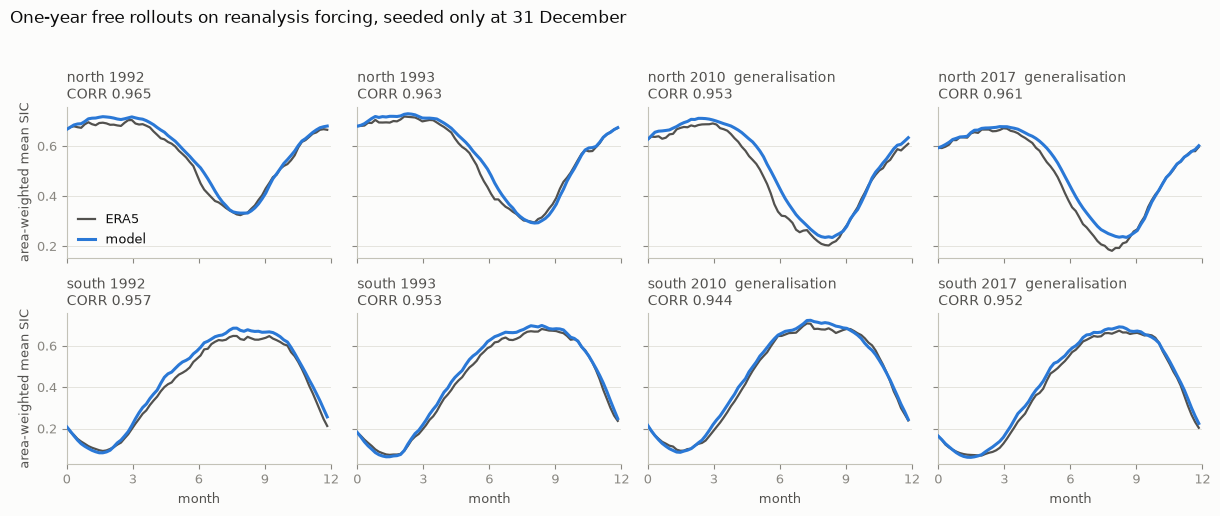

  wrote report_figures/rollout_field_vs_era5.png


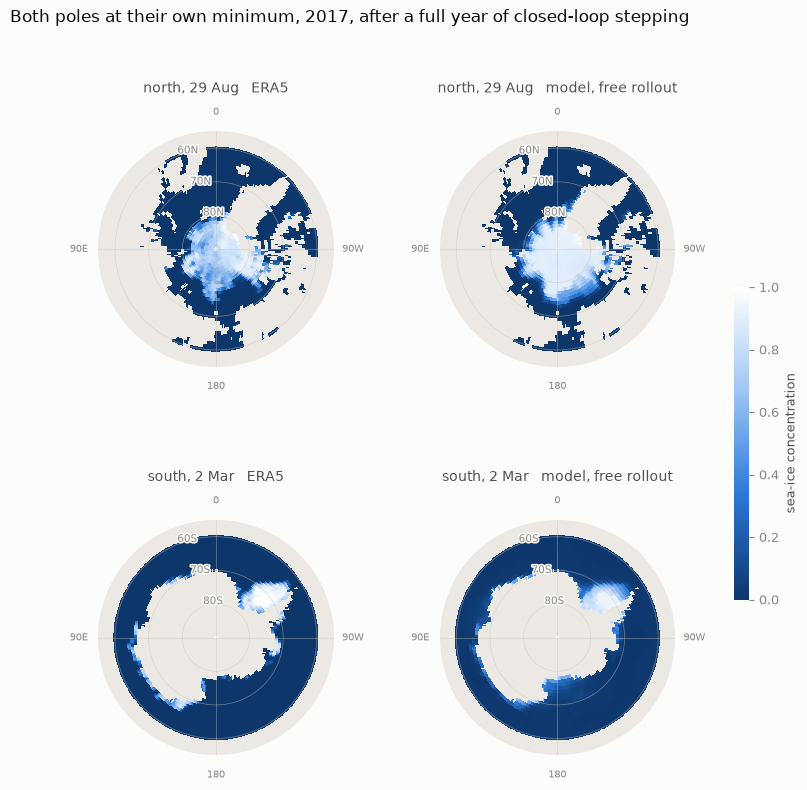

  wrote report_figures/rollout_error_map.png


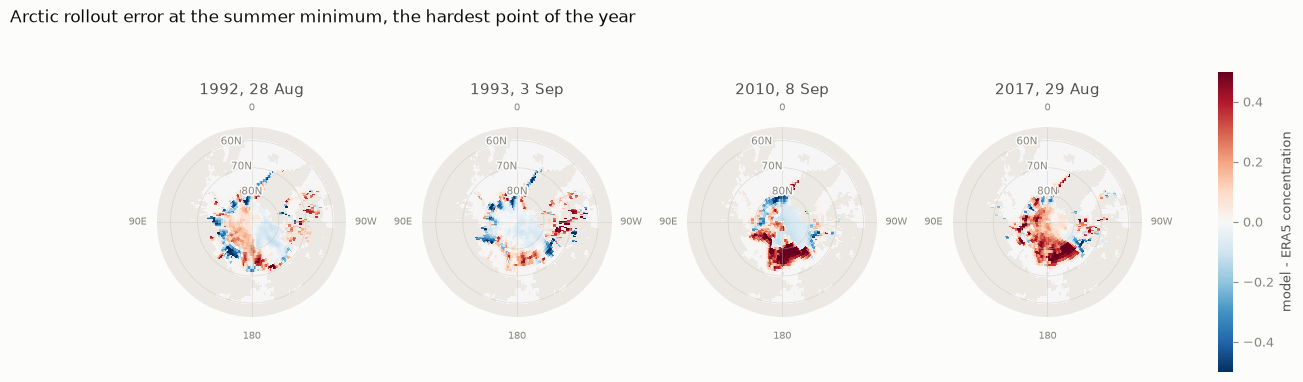

  wrote report_figures/rollout_2017_north.mp4  (2.4 MB)


  wrote report_figures/rollout_2017_north.gif  (1.5 MB, 73 frames, 5 days each)


  wrote report_figures/rollout_2017_south.mp4  (3.1 MB)


  wrote report_figures/rollout_2017_south.gif  (1.8 MB, 73 frames, 5 days each)


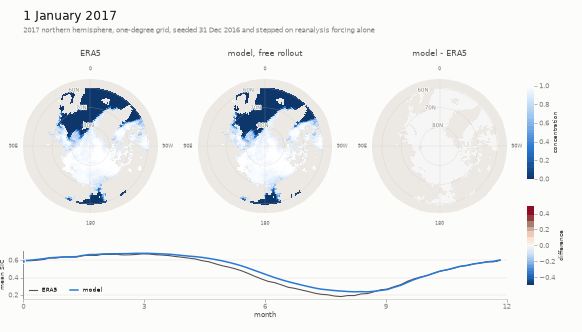

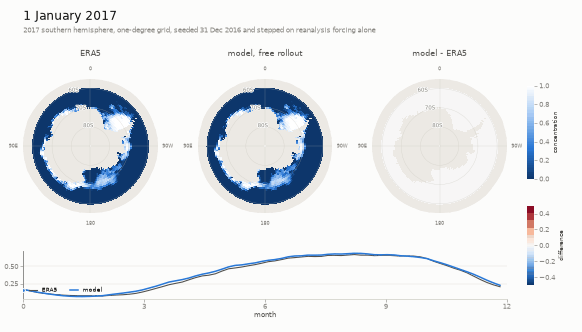

In [5]:
if not have_weights():
    needs_weights("§14 the figures and the animations")
else:
    import datetime
    import matplotlib
    matplotlib.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
        "xtick.color": "#898781", "ytick.color": "#898781",
        "text.color": "#0b0b0b", "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
        "axes.titlesize": 10.5, "axes.labelsize": 9, "font.size": 9,
        "axes.spines.top": False, "axes.spines.right": False, "savefig.facecolor": "#fcfcfb",
    })
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap
    import matplotlib.patheffects as pe

    FIGDIR = ROOT / "report_figures"; FIGDIR.mkdir(exist_ok=True)
    MODEL_C, ERA5_C, MUTED, INK2 = "#2a78d6", "#52514e", "#898781", "#52514e"
    # ice reads WHITE, open water dark: the convention every sea-ice figure uses, and the one
    # that makes the ice edge legible without a legend. Land and invalid cells take the page's
    # own neutral so they never read as a concentration.
    ICE = LinearSegmentedColormap.from_list("ice", ["#0d366b", "#2a78d6", "#9ec5f4", "#ffffff"])
    ICE.set_bad("#ece9e4")   # land and invalid cells, kept light so they recede
    ERR = plt.get_cmap("RdBu_r").copy(); ERR.set_bad("#ece9e4")

    def _save(fig, name):
        fig.savefig(FIGDIR / (name + ".png"), dpi=150, bbox_inches="tight")
        print("  wrote " + rel(FIGDIR / (name + ".png")))

    def polar_grid(lat, hemi="north"):
        """A lat-lon cap drawn from above the pole needs no projection library: the azimuth is
        the longitude and the radius is the co-latitude. Returns (theta, r) for pcolormesh, with
        the seam closed so there is no wedge at the date line. In the south the co-latitude is
        measured from the south pole instead, and the rows already ascend, so neither array is
        reversed there."""
        r = (90.0 - lat[::-1]) if hemi == "north" else (90.0 + lat)
        th = np.radians(np.append(np.arange(360.0), 360.0))
        return th, r

    def polar_field(F, lat, hemi="north"):
        F = np.asarray(F)
        if hemi == "north":
            F = F[::-1, :]
        return np.concatenate([F, F[:, :1]], axis=1)

    # 55N: the pack reaches about there at the March maximum, and everything further out is
    # land or permanently open water, which would otherwise fill half the disc with grey
    RMAX = 35.0

    def dress(a, rmax=RMAX, azim=True, hemi="north"):
        a.set_theta_zero_location("N"); a.set_theta_direction(1)
        a.set_rlim(0, rmax); a.set_rticks([10, 20, 30])
        # the latitude labels sit over dark ocean, so they carry the surface colour as a halo
        sfx = "N" if hemi == "north" else "S"
        for lb in a.set_yticklabels([f"80{sfx}", f"70{sfx}", f"60{sfx}"],
                                    color=MUTED, fontsize=7.5):
            lb.set_path_effects([pe.withStroke(linewidth=2.2, foreground="#fcfcfb")])
        a.set_xticks(np.radians([0, 90, 180, 270]))
        a.set_xticklabels(["0", "90E", "180", "90W"] if azim else ["", "", "", ""],
                          color=MUTED, fontsize=7.5)
        a.grid(color="#c3c2b7", lw=0.5, alpha=0.55)
        a.spines["polar"].set_visible(False)

    # ---- 1. the seasonal cycle it actually produces, area-weighted -------------------------
    yrs = [y for y, _, _ in TEST_YEARS]
    fig, ax = plt.subplots(2, len(yrs), figsize=(3.05 * len(yrs), 5.2), sharex=True, sharey="row")
    for r_, hemi in enumerate(("north", "south")):
        for c, yr in enumerate(yrs):
            a = ax[r_, c]; d = ROLL[(hemi, yr)]
            t = np.arange(len(d["era5"])) * 5 / 365.0 * 12
            a.grid(axis="y"); a.set_axisbelow(True)
            a.plot(t, d["era5"], "-", color=ERA5_C, lw=1.6, zorder=2, label="ERA5")
            a.plot(t, d["model"], "-", color=MODEL_C, lw=2.2, zorder=3, label="model")
            a.set_xlim(0, 12); a.set_xticks([0, 3, 6, 9, 12])
            a.set_title(f"{hemi} {yr}" + ("" if d["tag"] == "in distribution" else "  generalisation")
                        + f"\nCORR {d['corr']:.3f}", loc="left", color=INK2, fontsize=10)
            if r_ == 1: a.set_xlabel("month")
            if c == 0: a.set_ylabel("area-weighted mean SIC")
            if (r_, c) == (0, 0):
                a.legend(frameon=False, loc="lower left", fontsize=9, handlelength=1.4)
    fig.suptitle("One-year free rollouts on reanalysis forcing, seeded only at 31 December",
                 x=0.005, ha="left", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    _save(fig, "rollout_seasonal_cycle"); plt.show()

    # ---- 2. the field itself, from above each pole, at that hemisphere's minimum ------------
    yr0 = yrs[-1]
    fig, ax = plt.subplots(2, 2, figsize=(8.4, 8.6), subplot_kw={"projection": "polar"})
    for row, hemi in enumerate(("north", "south")):
        d = ROLL[(hemi, yr0)]; k = int(np.argmin(d["era5"]))
        th, rr = polar_grid(d["lat"], hemi); msk = d["mask"]
        when = (datetime.date(yr0, 1, 1) + datetime.timedelta(days=int(k * 5))).strftime("%d %b").lstrip("0")
        for a, (F, nm) in zip(ax[row], ((d["truth"][k], "ERA5"), (d["field"][k], "model, free rollout"))):
            im = a.pcolormesh(th, rr, polar_field(np.where(msk, F, np.nan), d["lat"], hemi),
                              shading="auto", cmap=ICE, vmin=0, vmax=1)
            dress(a, hemi=hemi)
            a.set_title(f"{hemi}, {when}   {nm}", color=INK2, y=1.13, fontsize=10)
    fig.subplots_adjust(wspace=0.45, hspace=0.42)
    cb = fig.colorbar(im, ax=ax, fraction=0.024, pad=0.09)
    cb.set_label("sea-ice concentration", color=INK2); cb.outline.set_visible(False)
    fig.suptitle(f"Both poles at their own minimum, {yr0}, after a full year of closed-loop stepping",
                 x=0.02, y=1.00, ha="left", fontsize=12)
    _save(fig, "rollout_field_vs_era5"); plt.show()

    # ---- 3. where the error lives, same view ------------------------------------------------
    fig, ax = plt.subplots(1, len(yrs), figsize=(3.5 * len(yrs), 3.9),
                           subplot_kw={"projection": "polar"})
    for c, yr in enumerate(yrs):
        dd = ROLL[("north", yr)]; a = ax[c]
        kk = int(np.argmin(dd["era5"]))
        e = np.where(dd["mask"], dd["field"][kk] - dd["truth"][kk], np.nan)
        th2, rr2 = polar_grid(dd["lat"])
        im = a.pcolormesh(th2, rr2, polar_field(e, dd["lat"]), shading="auto",
                          cmap=ERR, vmin=-0.5, vmax=0.5)
        dress(a)
        w2 = (datetime.date(yr, 1, 1) + datetime.timedelta(days=int(kk * 5))).strftime("%d %b").lstrip("0")
        a.set_title(f"{yr}, {w2}", color=INK2, y=1.13)   # fixed y: pad drifts on polar axes
    fig.subplots_adjust(wspace=0.40)
    cb = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.07)
    cb.set_label("model - ERA5 concentration", color=INK2); cb.outline.set_visible(False)
    fig.suptitle("Arctic rollout error at the summer minimum, the hardest point of the year",
                 x=0.02, y=1.04, ha="left", fontsize=12)
    _save(fig, "rollout_error_map"); plt.show()

    # ---- 4. the whole year as a video, one per pole -----------------------------------------
    # The rollout this animates is the deployment configuration: the ONE DEGREE grid, with the
    # gradient and curvature columns referenced to the fixed two-degree arc (cross_for picks the
    # operator the weights were trained on, and §13 sets spatial_block=1). Nothing here is a
    # coarsened or smoothed view of a different calculation.
    MAKE_VIDEO = True        # about four minutes for both; set False to skip
    if MAKE_VIDEO:
        from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
        from IPython.display import Image as _Image, display as _display
        made = {}
        for hemi in ("north", "south"):
            dv = ROLL[(hemi, yr0)]
            nfr = dv["field"].shape[0]
            thv, rv = polar_grid(dv["lat"], hemi); mv = dv["mask"]
            tcur = np.arange(len(dv["era5"])) * 5 / 365.0 * 12

            figv = plt.figure(figsize=(11.2, 6.4))
            # top is well below the header: the panel titles sit above their axes and would
            # otherwise be written straight through the subtitle line
            gs = figv.add_gridspec(2, 3, height_ratios=[3.1, 1.0], hspace=0.32, wspace=0.30,
                                   left=0.04, right=0.87, top=0.78, bottom=0.10)
            pa = [figv.add_subplot(gs[0, j], projection="polar") for j in range(3)]
            meshes = []
            for a, (nm, cm, lo, hi) in zip(pa, (("ERA5", ICE, 0, 1),
                                                ("model, free rollout", ICE, 0, 1),
                                                ("model - ERA5", ERR, -0.5, 0.5))):
                m_ = a.pcolormesh(thv, rv,
                                  polar_field(np.where(mv, dv["truth"][0], np.nan), dv["lat"], hemi),
                                  shading="nearest", cmap=cm, vmin=lo, vmax=hi)
                dress(a, hemi=hemi); a.set_title(nm, color=INK2, y=1.14); meshes.append(m_)
            cax1 = figv.add_axes([0.905, 0.46, 0.012, 0.28])
            cb1 = figv.colorbar(meshes[0], cax=cax1); cb1.outline.set_visible(False)
            cb1.set_label("concentration", color=INK2, fontsize=8.5)
            cax2 = figv.add_axes([0.905, 0.14, 0.012, 0.24])
            cb2 = figv.colorbar(meshes[2], cax=cax2); cb2.outline.set_visible(False)
            cb2.set_label("difference", color=INK2, fontsize=8.5)

            # the seasonal cycle underneath, with a marker showing where in the year the maps are
            ax_t = figv.add_subplot(gs[1, :])
            ax_t.grid(axis="y"); ax_t.set_axisbelow(True)
            ax_t.plot(tcur, dv["era5"], "-", color=ERA5_C, lw=1.5, label="ERA5")
            ax_t.plot(tcur, dv["model"], "-", color=MODEL_C, lw=2.1, label="model")
            ax_t.set_xlim(0, 12); ax_t.set_xticks([0, 3, 6, 9, 12])
            ax_t.set_xlabel("month", labelpad=1); ax_t.set_ylabel("mean SIC", fontsize=8.5)
            ax_t.legend(frameon=False, loc="lower left", fontsize=8.5, handlelength=1.3, ncol=2)
            cursor = ax_t.axvline(tcur[0], color=MUTED, lw=1.2, zorder=4)
            dot_e, = ax_t.plot([tcur[0]], [dv["era5"][0]], "o", color=ERA5_C, ms=5,
                               mec="#fcfcfb", mew=1.2, zorder=5)
            dot_m, = ax_t.plot([tcur[0]], [dv["model"][0]], "o", color=MODEL_C, ms=5,
                               mec="#fcfcfb", mew=1.2, zorder=5)
            head = figv.text(0.04, 0.965, "", ha="left", va="top", fontsize=16, color="#0b0b0b")
            figv.text(0.04, 0.918, f"{yr0} {hemi}ern hemisphere, one-degree grid, seeded "
                                   f"31 Dec {yr0-1} and stepped on reanalysis forcing alone",
                      ha="left", va="top", fontsize=9.5, color=MUTED)

            def frame(i, dv=dv, mv=mv, hemi=hemi, meshes=meshes, head=head,
                      cursor=cursor, dot_e=dot_e, dot_m=dot_m, tcur=tcur):
                fields = (dv["truth"][i], dv["field"][i], dv["field"][i] - dv["truth"][i])
                for m_, F in zip(meshes, fields):
                    m_.set_array(polar_field(np.where(mv, F, np.nan), dv["lat"], hemi).ravel())
                day = datetime.date(yr0, 1, 1) + datetime.timedelta(days=int(i * 5))
                head.set_text(day.strftime("%d %B %Y").lstrip("0"))
                cursor.set_xdata([tcur[i], tcur[i]])
                dot_e.set_data([tcur[i]], [dv["era5"][i]])
                dot_m.set_data([tcur[i]], [dv["model"][i]])
                return meshes + [head, cursor, dot_e, dot_m]

            anim = FuncAnimation(figv, frame, frames=nfr, blit=False)
            try:
                mp4 = FIGDIR / f"rollout_{yr0}_{hemi}.mp4"
                anim.save(mp4, writer=FFMpegWriter(fps=10, bitrate=3600), dpi=130)
                print(f"  wrote {rel(mp4)}  ({mp4.stat().st_size / 1e6:.1f} MB)")
            except Exception as exc:
                print(f"  no mp4 ({type(exc).__name__}: {exc})")
            # a GIF as well, at a size that can be embedded in this notebook and in a README:
            # neither renders an mp4, and a figure nobody can see is not a result
            gif = FIGDIR / f"rollout_{yr0}_{hemi}.gif"
            anim.save(gif, writer=PillowWriter(fps=10), dpi=52)
            plt.close(figv)
            made[hemi] = gif
            print(f"  wrote {rel(gif)}  ({gif.stat().st_size / 1e6:.1f} MB, {nfr} frames, 5 days each)")
        for hemi, g in made.items():
            _display(_Image(filename=str(g)))


## 15. Single-step diagnostic figures

This section plots the single-step evaluation metrics and diagnostics computed in the preceding sections, using their existing result arrays. The figures are also saved in `report_figures/`.


  wrote report_figures/offline_skill_bias_by_sic.png


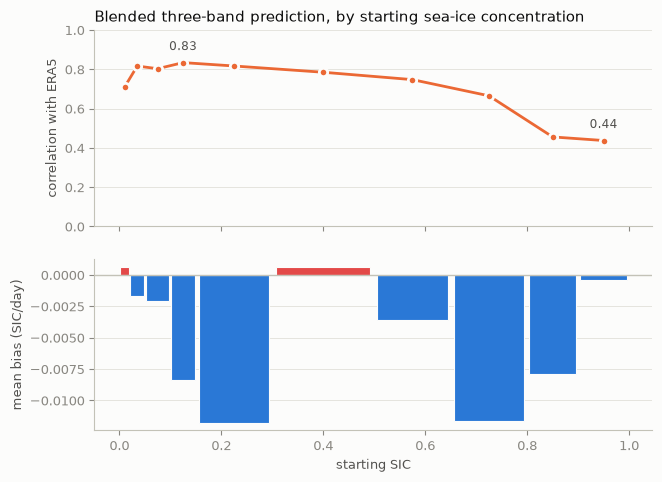

  wrote report_figures/offline_band_skill.png


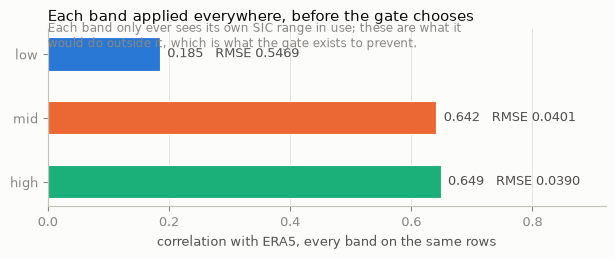

  wrote report_figures/offline_change_gate.png


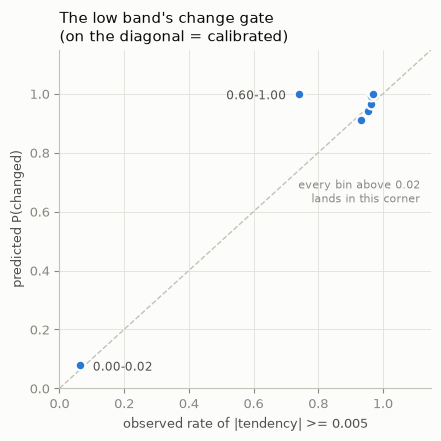

  wrote report_figures/offline_constraints.png


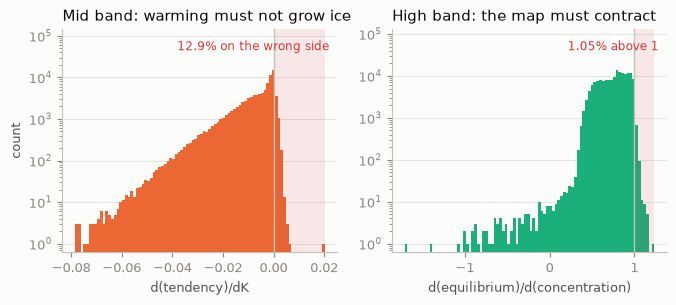

In [17]:
if not have_weights():
    needs_weights("§15 the single-step diagnostics")
else:
    import matplotlib
    matplotlib.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
        "xtick.color": "#898781", "ytick.color": "#898781",
        "text.color": "#0b0b0b", "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
        "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9.5,
        "axes.spines.top": False, "axes.spines.right": False, "savefig.facecolor": "#fcfcfb",
    })
    import matplotlib.pyplot as plt

    FIGDIR = ROOT / "report_figures"; FIGDIR.mkdir(exist_ok=True)
    # the first three categorical slots of the reference palette -- the only three that validate
    # on ALL pairs. Aqua is below 3:1 on this surface, so every band is also direct-labelled.
    BAND_C = {"low": "#2a78d6", "mid": "#eb6834", "high": "#1baf7a"}
    NEG, POS, CRIT, MUTED, INK2 = "#2a78d6", "#e34948", "#d03b3b", "#898781", "#52514e"

    def _save(fig, name):
        fig.savefig(FIGDIR / (name + ".png"), dpi=150, bbox_inches="tight")
        print("  wrote " + rel(FIGDIR / (name + ".png")))

    # ---- 1. skill and bias against the starting SIC
    ctr, corr, bias, wid = [], [], [], []
    for lo, hi in BINS:
        m = ok_r & (A >= lo) & (A < hi)
        if m.sum() < 50:
            continue
        hi_ = min(hi, 1.0)
        ctr.append((lo + hi_) / 2); wid.append((hi_ - lo) * 0.92)
        corr.append(float(np.corrcoef(BL[m], OBS[m])[0, 1]))
        bias.append(float((BL[m] - OBS[m]).mean()))
    fig, ax = plt.subplots(2, 1, figsize=(7.2, 5.2), sharex=True,
                           gridspec_kw={"height_ratios": [1.15, 1], "hspace": 0.18})
    ax[0].grid(axis="y"); ax[0].set_axisbelow(True)
    ax[0].plot(ctr, corr, "-", color=BAND_C["mid"], lw=2, zorder=2)
    ax[0].plot(ctr, corr, "o", color=BAND_C["mid"], ms=6, mec="#fcfcfb", mew=2, zorder=3)
    ax[0].set_ylim(0, 1); ax[0].set_ylabel("correlation with ERA5")
    ax[0].set_title("Blended three-band prediction, by starting sea-ice concentration", loc="left")
    for x, y in zip(ctr, corr):
        if y in (max(corr), min(corr)):
            ax[0].annotate(format(y, ".2f"), (x, y), textcoords="offset points", xytext=(0, 9),
                           ha="center", fontsize=8.5, color=INK2)
    ax[1].grid(axis="y"); ax[1].set_axisbelow(True)
    ax[1].axhline(0, color="#c3c2b7", lw=1)
    ax[1].bar(ctr, bias, width=wid, color=[POS if b > 0 else NEG for b in bias],
              edgecolor="#fcfcfb", linewidth=0.8)
    ax[1].set_ylabel("mean bias (SIC/day)"); ax[1].set_xlabel("starting SIC")
    _save(fig, "offline_skill_bias_by_sic"); plt.show()

    # ---- 2. the three bands on a common row set, before the gate chooses
    rows = [(b, float(np.corrcoef(P[b][ok_r], OBS[ok_r])[0, 1]),
             float(np.sqrt(((P[b][ok_r] - OBS[ok_r]) ** 2).mean()))) for b in ("low", "mid", "high")]
    fig, ax = plt.subplots(figsize=(7.2, 2.3))
    ax.grid(axis="x"); ax.set_axisbelow(True)
    for i, (b, c, r) in enumerate(rows):
        ax.barh(i, c, height=0.52, color=BAND_C[b], edgecolor="#fcfcfb", linewidth=0.8)
        ax.text(c + 0.012, i, format(c, ".3f") + "   RMSE " + format(r, ".4f"),
                va="center", fontsize=9, color=INK2)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([b for b, _, _ in rows])
    ax.set_xlim(0, max(c for _, c, _ in rows) * 1.42); ax.invert_yaxis()
    ax.set_xlabel("correlation with ERA5, every band on the same rows")
    ax.set_title("Each band applied everywhere, before the gate chooses", loc="left")
    ax.text(0, -0.52, "Each band only ever sees its own SIC range in use; these are what it\nwould do outside it, which is what the gate exists to prevent.",
            transform=ax.get_yaxis_transform(), fontsize=8.5, color=MUTED, va="top")
    _save(fig, "offline_band_skill"); plt.show()

    # ---- 3. the low band's change gate: predicted against observed
    pb, tb, lab = [], [], []
    for lo, hi in [(0, .02), (.02, .05), (.05, .10), (.10, .15), (.15, .30), (.30, .60), (.60, 1.001)]:
        m = ok_r & (A >= lo) & (A < hi)
        if m.sum() < 50:
            continue
        pb.append(float(p_ch[m].mean())); tb.append(float(truth[m].mean())); lab.append((lo, hi))
    fig, ax = plt.subplots(figsize=(4.8, 4.4))
    ax.grid(); ax.set_axisbelow(True)
    lim = max(max(pb), max(tb)) * 1.15
    ax.plot([0, lim], [0, lim], "--", color="#c3c2b7", lw=1, zorder=1)
    ax.plot(tb, pb, "o", color=BAND_C["low"], ms=7, mec="#fcfcfb", mew=1.6, zorder=3)
    # selective labels only: every bin above 0.02 lands in the same top-right corner
    for k in (0, len(tb) - 1):
        lo, hi = lab[k]
        ax.annotate(format(lo, ".2f") + "-" + format(min(hi, 1.0), ".2f"), (tb[k], pb[k]),
                    textcoords="offset points",
                    xytext=(9, -4) if k == 0 else (-9, -4), fontsize=8.5, color=INK2,
                    ha="left" if k == 0 else "right")
    ax.text(0.97, 0.62, "every bin above 0.02\nlands in this corner", transform=ax.transAxes,
            fontsize=8, color=MUTED, ha="right", va="top")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("observed rate of |tendency| >= " + str(TAU))
    ax.set_ylabel("predicted P(changed)")
    ax.set_title("The low band's change gate\n(on the diagonal = calibrated)", loc="left")
    _save(fig, "offline_change_gate"); plt.show()

    # ---- 4. the two trained constraints, as distributions rather than one fraction
    fig, ax = plt.subplots(1, 2, figsize=(7.8, 2.9))
    for a_ in ax:
        a_.grid(axis="y"); a_.set_axisbelow(True)
    ax[0].hist(Dd, bins=90, color=BAND_C["mid"], edgecolor="none")
    ax[0].axvline(0, color="#c3c2b7", lw=1)
    ax[0].axvspan(0, max(float(Dd.max()), 1e-9), color=CRIT, alpha=0.10, lw=0)
    ax[0].set_yscale("log"); ax[0].set_xlabel("d(tendency)/dK"); ax[0].set_ylabel("count")
    ax[0].set_ylim(top=ax[0].get_ylim()[1] * 6)   # headroom, so the label clears the bars
    ax[0].set_title("Mid band: warming must not grow ice", loc="left")
    ax[0].text(0.97, 0.95, format(float((Dd > 0).mean()), ".1%") + " on the wrong side",
               transform=ax[0].transAxes, ha="right", va="top", fontsize=8.5, color=CRIT)
    if len(DEQ):
        dq = np.concatenate(DEQ)
        ax[1].hist(dq, bins=90, color=BAND_C["high"], edgecolor="none")
        ax[1].axvline(1.0, color="#c3c2b7", lw=1)
        ax[1].axvspan(1.0, max(float(dq.max()), 1.001), color=CRIT, alpha=0.10, lw=0)
        ax[1].set_yscale("log"); ax[1].set_xlabel("d(equilibrium)/d(concentration)")
        ax[1].set_ylim(top=ax[1].get_ylim()[1] * 6)
        ax[1].set_title("High band: the map must contract", loc="left")
        ax[1].text(0.97, 0.95, format(float((dq > 1).mean()), ".2%") + " above 1",
                   transform=ax[1].transAxes, ha="right", va="top", fontsize=8.5, color=CRIT)
    else:
        ax[1].set_axis_off()
        ax[1].text(.5, .5, "run section 11 first", ha="center", va="center", color=MUTED)
    _save(fig, "offline_constraints"); plt.show()
